In [1]:
from google.colab import files
uploaded = files.upload()
zip_files = [name for name in uploaded if name.lower().endswith(".zip")]
assert zip_files, "Please upload the v0.2 project ZIP file"
zip_name = zip_files[0]
print("Uploaded:", zip_name)

Saving V2X-Cooperative-Perception-v0.2.zip to V2X-Cooperative-Perception-v0.2.zip
Uploaded: V2X-Cooperative-Perception-v0.2.zip


In [2]:
import zipfile
import os

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall('/content/')

print("Project extracted successfully!")
print(os.listdir('/content/'))

Project extracted successfully!
['.config', 'V2X-Cooperative-Perception', 'V2X-Cooperative-Perception-v0.2.zip', 'sample_data']


In [3]:
%cd /content/V2X-Cooperative-Perception
!pip install -r requirements.txt
!python experiments/run_occlusion.py

/content/V2X-Cooperative-Perception
Frames: 121; pedestrian radar detections: 0/121; LiDAR detections: 73/121; infrastructure-only detections: 73/121
Figure: /content/V2X-Cooperative-Perception/results/occlusion_v02.png


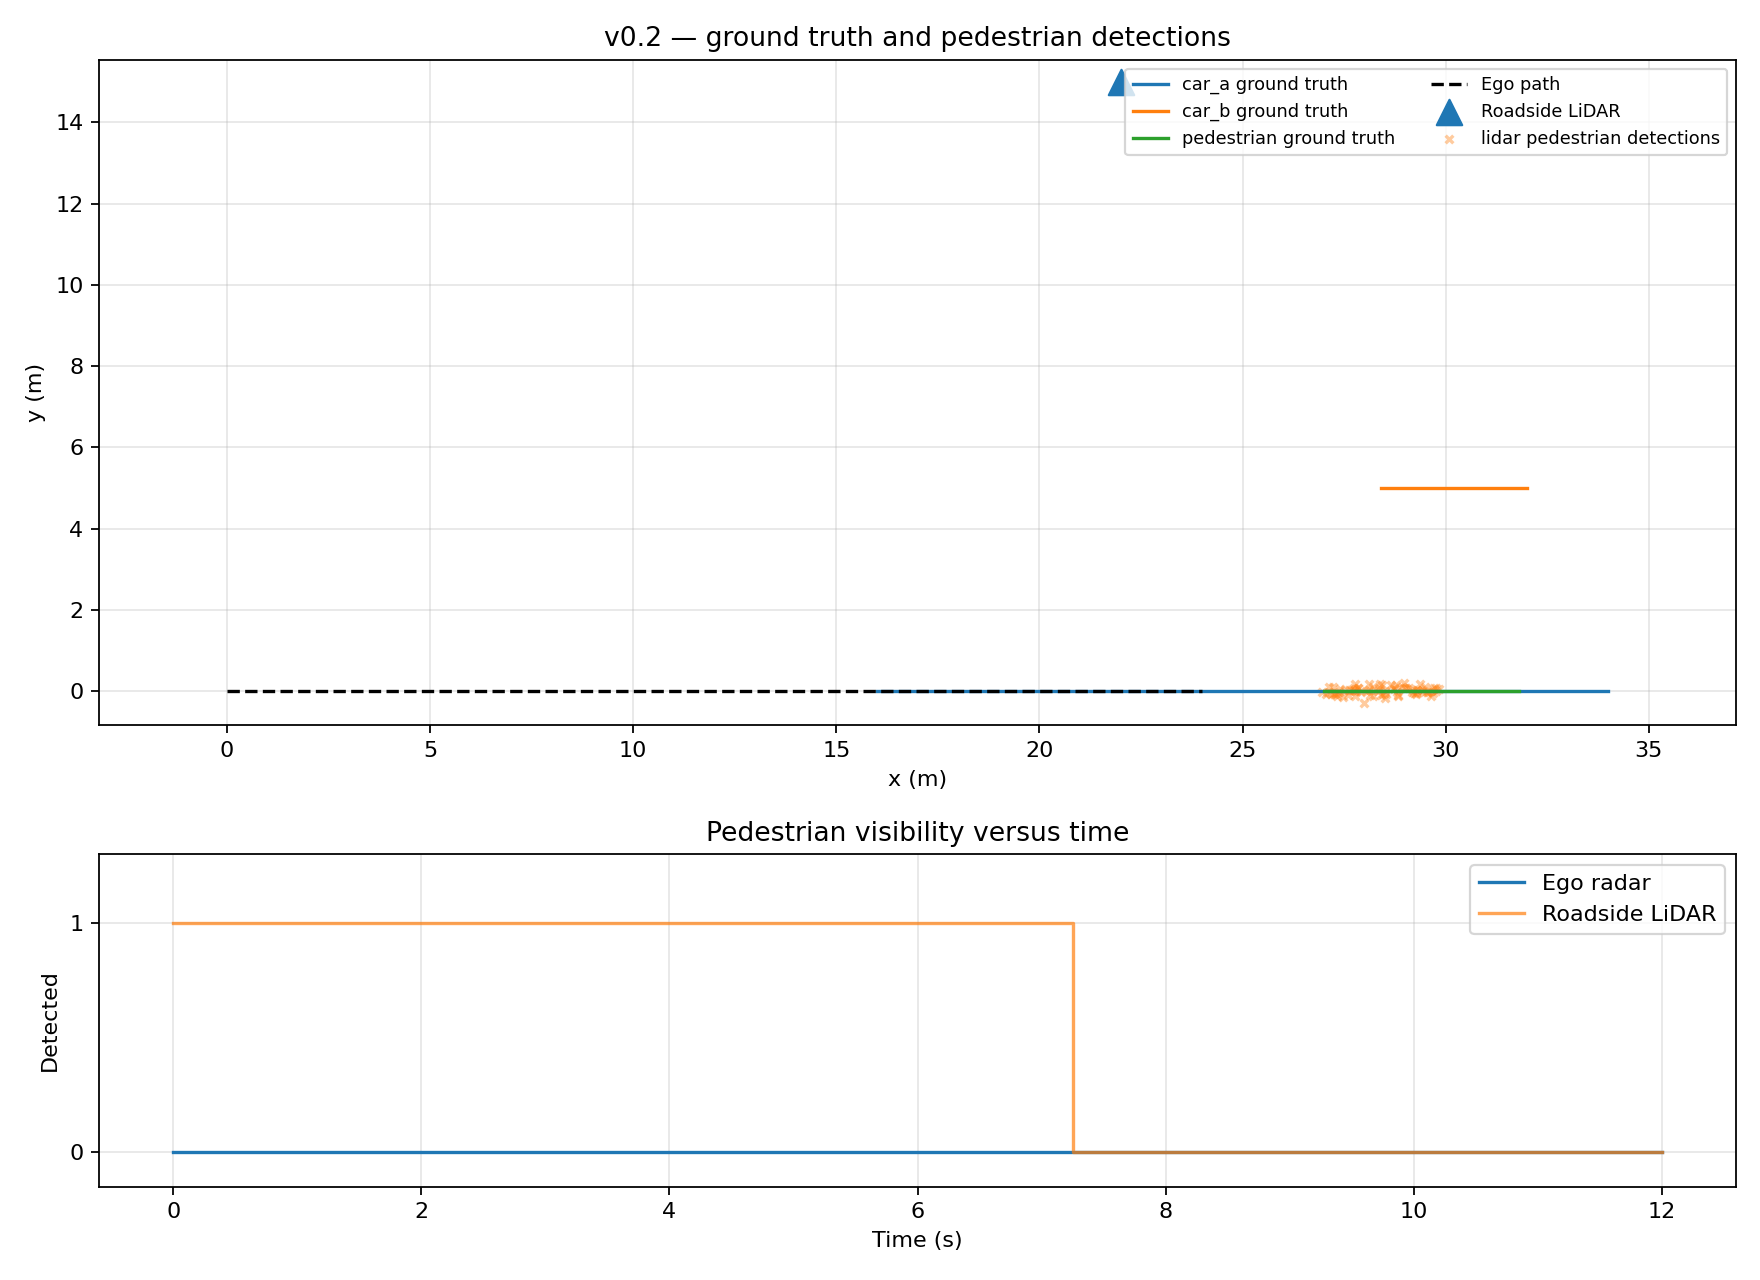

In [4]:
from IPython.display import Image, display

display(Image(
    filename="/content/V2X-Cooperative-Perception/results/occlusion_v02.png"
))

In [5]:
!python -m pytest -q

......                                                                   [100%]
6 passed in 0.18s


In [6]:
import numpy as np
import heapq
from dataclasses import dataclass

@dataclass
class V2XMessage:
    timestamp: float
    object_id: int
    position: np.ndarray

class V2XChannel:
    def __init__(self, latency=0.1, packet_loss=0.05, seed=42):
        self.latency = latency
        self.packet_loss = packet_loss
        self.rng = np.random.default_rng(seed)
        self.queue = []
        self.counter = 0

    def send(self, message):
        if self.rng.random() < self.packet_loss:
            return False

        arrival_time = message.timestamp + self.latency

        heapq.heappush(
            self.queue,
            (arrival_time, self.counter, message)
        )
        self.counter += 1
        return True

    def receive(self, current_time):
        received = []

        while self.queue and self.queue[0][0] <= current_time:
            _, _, message = heapq.heappop(self.queue)
            received.append(message)

        return received

In [7]:
channel = V2XChannel(latency=0.1, packet_loss=0.0)

message = V2XMessage(
    timestamp=1.0,
    object_id=1,
    position=np.array([15.0, 3.0])
)

channel.send(message)

print("At t=1.05:", channel.receive(1.05))
print("At t=1.10:", channel.receive(1.10))

At t=1.05: []
At t=1.10: [V2XMessage(timestamp=1.0, object_id=1, position=array([15.,  3.]))]


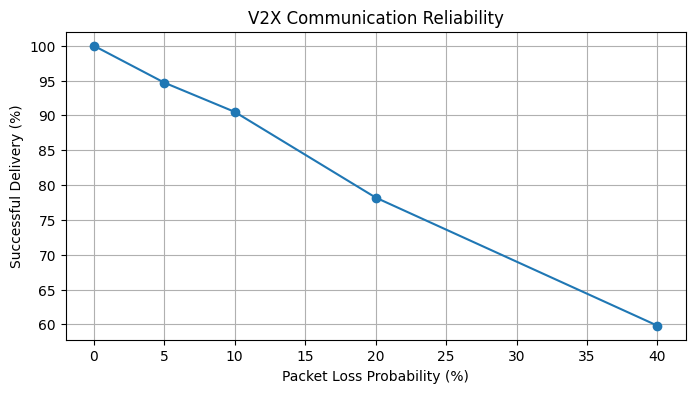

Loss=0% -> Delivery=100.0%
Loss=5% -> Delivery=94.7%
Loss=10% -> Delivery=90.5%
Loss=20% -> Delivery=78.2%
Loss=40% -> Delivery=59.8%


In [8]:
import numpy as np
import matplotlib.pyplot as plt

latencies = [0.0, 0.05, 0.1, 0.2, 0.5]
packet_losses = [0.0, 0.05, 0.1, 0.2, 0.4]

delivery_rates = []

for loss in packet_losses:
    channel = V2XChannel(
        latency=0.1,
        packet_loss=loss,
        seed=42
    )

    sent = 1000
    delivered = 0

    for i in range(sent):
        msg = V2XMessage(
            timestamp=i * 0.1,
            object_id=1,
            position=np.array([15.0, 3.0])
        )
        channel.send(msg)

    delivered = len(channel.receive(200.0))
    delivery_rates.append(delivered / sent * 100)

plt.figure(figsize=(8, 4))
plt.plot(
    np.array(packet_losses) * 100,
    delivery_rates,
    marker="o"
)
plt.xlabel("Packet Loss Probability (%)")
plt.ylabel("Successful Delivery (%)")
plt.title("V2X Communication Reliability")
plt.grid(True)
plt.show()

for loss, delivery in zip(packet_losses, delivery_rates):
    print(f"Loss={loss:.0%} -> Delivery={delivery:.1f}%")

LiDAR measurements generated: 73
V2X packets transmitted: 68
V2X packets received: 68
Delivery rate: 93.2%


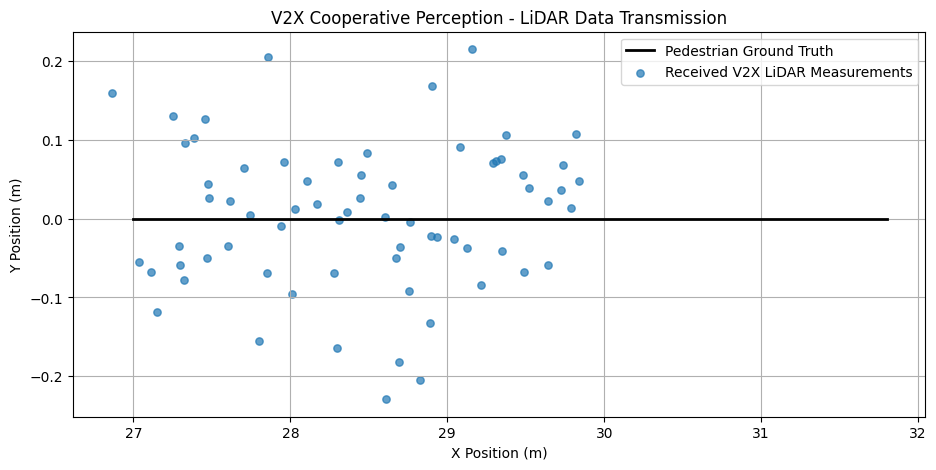

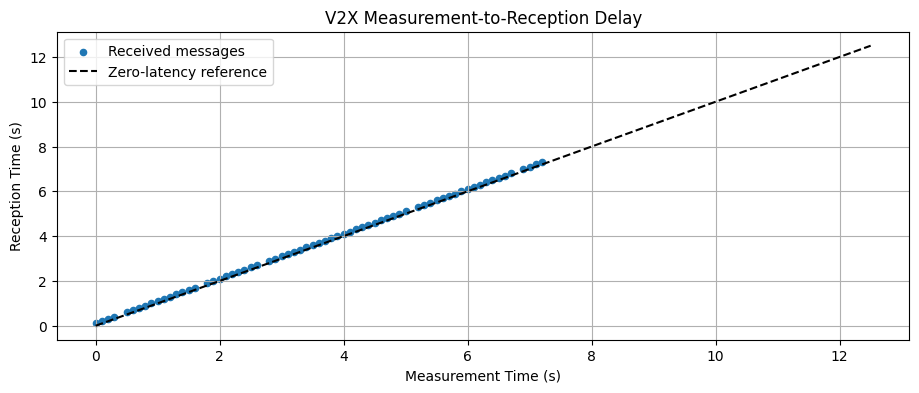

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from src.simulation.cooperative_scenario import frames
from src.sensors.cooperative_sensors import sample_sensor

rng = np.random.default_rng(42)

roadside = np.array([22.0, 15.0])
channel = V2XChannel(
    latency=0.1,
    packet_loss=0.10,
    seed=42
)

timestamps = []
ground_truth = []
received_positions = []
received_times = []
measurement_times = []

generated = 0
transmitted = 0

for frame in frames():
    t = frame.t

    # Generate actual simulated LiDAR detections
    detections = sample_sensor(
        roadside,
        frame.targets,
        frame.blockers,
        rng,
        max_range=70.0,
        fov_deg=360.0,
        sigma_range=0.10,
        sigma_bearing=0.004,
        skip_blocker_for="car_a"
    )

    # Select pedestrian for this controlled experiment
    for detection in detections:
        if detection.target_id == "pedestrian":
            generated += 1

            message = V2XMessage(
                timestamp=t,
                object_id=1,
                position=detection.position.copy()
            )

            if channel.send(message):
                transmitted += 1

    # Receive messages available at the current time
    for message in channel.receive(t + 1e-8):
        received_positions.append(message.position.copy())
        received_times.append(t)
        measurement_times.append(message.timestamp)

    timestamps.append(t)
    ground_truth.append(frame.targets["pedestrian"].copy())

# Drain remaining messages after simulation end
for message in channel.receive(1000.0):
    received_positions.append(message.position.copy())
    received_times.append(message.timestamp + channel.latency)
    measurement_times.append(message.timestamp)

ground_truth = np.array(ground_truth)
received_positions = np.array(received_positions)
received_times = np.array(received_times)

print("LiDAR measurements generated:", generated)
print("V2X packets transmitted:", transmitted)
print("V2X packets received:", len(received_positions))

if generated:
    print(
        "Delivery rate:",
        f"{100 * len(received_positions) / generated:.1f}%"
    )

# Plot ground truth versus received V2X positions
plt.figure(figsize=(11, 5))

plt.plot(
    ground_truth[:, 0],
    ground_truth[:, 1],
    "k-",
    linewidth=2,
    label="Pedestrian Ground Truth"
)

if len(received_positions):
    plt.scatter(
        received_positions[:, 0],
        received_positions[:, 1],
        s=28,
        alpha=0.7,
        label="Received V2X LiDAR Measurements"
    )

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("V2X Cooperative Perception - LiDAR Data Transmission")
plt.grid(True)
plt.legend()
plt.show()

# Communication timeline
plt.figure(figsize=(11, 4))

plt.scatter(
    measurement_times,
    received_times,
    s=20,
    label="Received messages"
)

plt.plot(
    [0, 12.5],
    [0, 12.5],
    "k--",
    label="Zero-latency reference"
)

plt.xlabel("Measurement Time (s)")
plt.ylabel("Reception Time (s)")
plt.title("V2X Measurement-to-Reception Delay")
plt.grid(True)
plt.legend()
plt.show()

Naive KF RMSE:         0.0836 m
Latency-Aware KF RMSE: 0.0897 m
Evaluated frames:      73


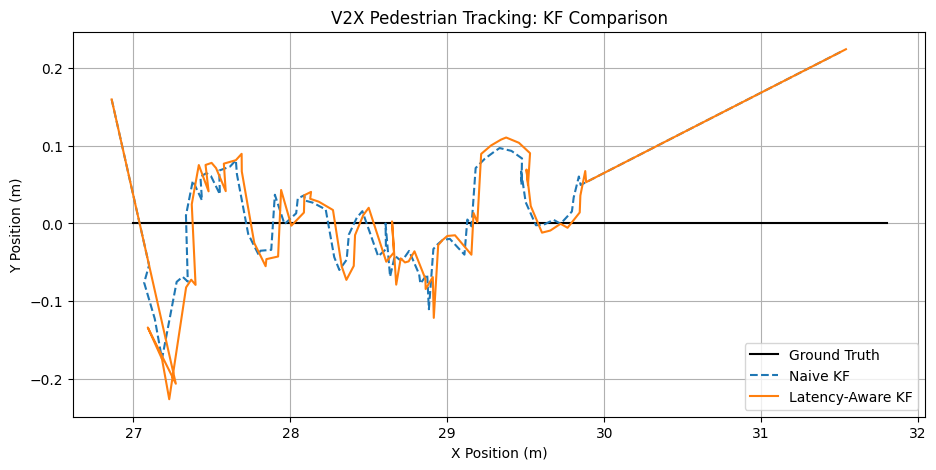

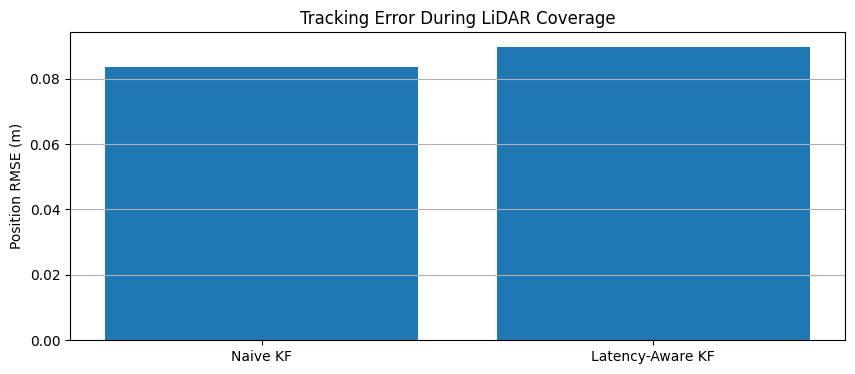

In [10]:
import numpy as np
import matplotlib.pyplot as plt

class CVKalmanFilter:
    def __init__(self, z, t):
        self.x = np.array([z[0], z[1], 0., 0.], dtype=float)
        self.P = np.diag([0.1, 0.1, 25., 25.])
        self.t = float(t)
        self.H = np.array([
            [1., 0., 0., 0.],
            [0., 1., 0., 0.]
        ])
        self.R = np.eye(2) * 0.15**2

    def predict(self, t):
        dt = float(t - self.t)
        if dt < -1e-8:
            raise ValueError("Time must be nondecreasing")
        dt = max(dt, 0.)

        F = np.eye(4)
        F[0, 2] = dt
        F[1, 3] = dt

        # White-acceleration process noise
        G = np.array([
            [dt**2 / 2, 0.],
            [0., dt**2 / 2],
            [dt, 0.],
            [0., dt]
        ])
        Q = G @ G.T * 1.0**2

        self.x = F @ self.x
        self.P = F @ self.P @ F.T + Q
        self.t = float(t)

    def update(self, z):
        z = np.asarray(z, dtype=float)
        innovation = z - self.H @ self.x
        S = self.H @ self.P @ self.H.T + self.R
        K = np.linalg.solve(S, self.H @ self.P).T

        self.x += K @ innovation

        I = np.eye(4)
        A = I - K @ self.H
        self.P = A @ self.P @ A.T + K @ self.R @ K.T


# Inputs from the previous Colab cell
packets = sorted(
    zip(received_times, measurement_times, received_positions),
    key=lambda p: p[0]
)

def estimate_at(current_time, latency_aware=False):
    # Only packets actually received by current_time
    available = [
        p for p in packets
        if p[0] <= current_time + 1e-8
    ]
    if not available:
        return np.full(4, np.nan)

    if latency_aware:
        # Replay measurements at their original timestamps.
        # This is a simple fixed-history OOSM implementation.
        events = sorted(available, key=lambda p: p[1])
    else:
        events = available

    first = events[0]
    initial_time = first[1] if latency_aware else first[0]
    kf = CVKalmanFilter(first[2], initial_time)

    for arrival, measured, position in events[1:]:
        event_time = measured if latency_aware else arrival
        kf.predict(event_time)
        kf.update(position)

    kf.predict(current_time)
    return kf.x.copy()


times = np.asarray(timestamps, dtype=float)
truth = np.asarray(ground_truth, dtype=float)

naive_states = np.array([
    estimate_at(t, False) for t in times
])

aware_states = np.array([
    estimate_at(t, True) for t in times
])

# Evaluate only while LiDAR has recent observations.
# Beyond this window both filters extrapolate without updates.
last_measurement = max(measurement_times)
valid = (
    (times <= last_measurement + 0.11)
    & np.isfinite(naive_states[:, 0])
    & np.isfinite(aware_states[:, 0])
)

def position_rmse(estimate, reference, mask):
    error = estimate[mask, :2] - reference[mask, :2]
    return np.sqrt(np.mean(np.sum(error**2, axis=1)))

naive_rmse = position_rmse(naive_states, truth, valid)
aware_rmse = position_rmse(aware_states, truth, valid)

print(f"Naive KF RMSE:         {naive_rmse:.4f} m")
print(f"Latency-Aware KF RMSE: {aware_rmse:.4f} m")
print(f"Evaluated frames:      {valid.sum()}")

plt.figure(figsize=(11, 5))
plt.plot(truth[:, 0], truth[:, 1], "k-", label="Ground Truth")
plt.plot(
    naive_states[:, 0], naive_states[:, 1],
    "--", label="Naive KF"
)
plt.plot(
    aware_states[:, 0], aware_states[:, 1],
    "-", label="Latency-Aware KF"
)
plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("V2X Pedestrian Tracking: KF Comparison")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))
plt.bar(
    ["Naive KF", "Latency-Aware KF"],
    [naive_rmse, aware_rmse]
)
plt.ylabel("Position RMSE (m)")
plt.title("Tracking Error During LiDAR Coverage")
plt.grid(axis="y")
plt.show()

Latency | Naive RMSE | Aware RMSE
--------------------------------
  0.00s |    0.1081 m |    0.1081 m
  0.05s |    0.1414 m |    0.1229 m
  0.10s |    0.1924 m |    0.1229 m
  0.20s |    0.3319 m |    0.1387 m
  0.30s |    0.4811 m |    0.1548 m
  0.50s |    0.7865 m |    0.1875 m


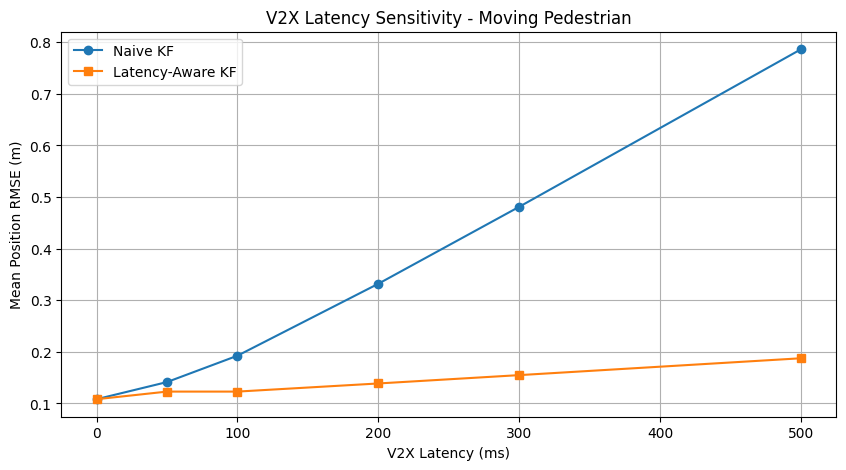

In [11]:
import numpy as np
import matplotlib.pyplot as plt

def moving_pedestrian_experiment(latency, seed=42):
    rng = np.random.default_rng(seed)
    dt = 0.1
    times = np.round(np.arange(0, 12.01, dt), 6)

    # Ground truth: constant velocity
    truth = np.column_stack((
        20.0 + 1.5 * times,
        2.0 + 0.4 * times
    ))

    channel = V2XChannel(
        latency=latency,
        packet_loss=0.10,
        seed=seed + 1000
    )

    packets = []
    naive_errors = []
    aware_errors = []

    for i, t in enumerate(times):
        z = truth[i] + rng.normal(0, 0.15, size=2)

        channel.send(V2XMessage(
            timestamp=float(t),
            object_id=1,
            position=z
        ))

        for msg in channel.receive(float(t) + 1e-8):
            packets.append((
                round(msg.timestamp + latency, 6),
                msg.timestamp,
                msg.position.copy()
            ))

        if len(packets) < 2:
            continue

        # Naive: process measurements at reception time
        naive = CVKalmanFilter(packets[0][2], packets[0][0])

        for arrival, measurement_time, position in packets[1:]:
            naive.predict(arrival)
            naive.update(position)

        naive.predict(t)

        # Latency-aware: replay using measurement timestamps
        ordered = sorted(packets, key=lambda p: p[1])
        aware = CVKalmanFilter(ordered[0][2], ordered[0][1])

        for arrival, measurement_time, position in ordered[1:]:
            aware.predict(measurement_time)
            aware.update(position)

        aware.predict(t)

        # Skip initial transient; evaluate at common times
        if t >= 3.0:
            naive_errors.append(
                np.sum((naive.x[:2] - truth[i])**2)
            )
            aware_errors.append(
                np.sum((aware.x[:2] - truth[i])**2)
            )

    return (
        np.sqrt(np.mean(naive_errors)),
        np.sqrt(np.mean(aware_errors))
    )


latencies = [0, 0.05, 0.1, 0.2, 0.3, 0.5]
seeds = range(20)

naive_results = []
aware_results = []

for latency in latencies:
    results = np.array([
        moving_pedestrian_experiment(latency, seed)
        for seed in seeds
    ])

    naive_results.append(np.mean(results[:, 0]))
    aware_results.append(np.mean(results[:, 1]))

print("Latency | Naive RMSE | Aware RMSE")
print("--------------------------------")

for d, n, a in zip(latencies, naive_results, aware_results):
    print(f"{d:6.2f}s | {n:9.4f} m | {a:9.4f} m")

plt.figure(figsize=(10, 5))

plt.plot(
    np.array(latencies) * 1000,
    naive_results,
    "o-",
    label="Naive KF"
)

plt.plot(
    np.array(latencies) * 1000,
    aware_results,
    "s-",
    label="Latency-Aware KF"
)

plt.xlabel("V2X Latency (ms)")
plt.ylabel("Mean Position RMSE (m)")
plt.title("V2X Latency Sensitivity - Moving Pedestrian")
plt.grid(True)
plt.legend()
plt.show()

Total frames: 121
Radar visible: 0
LiDAR visible: 121
Infrastructure-only: 121


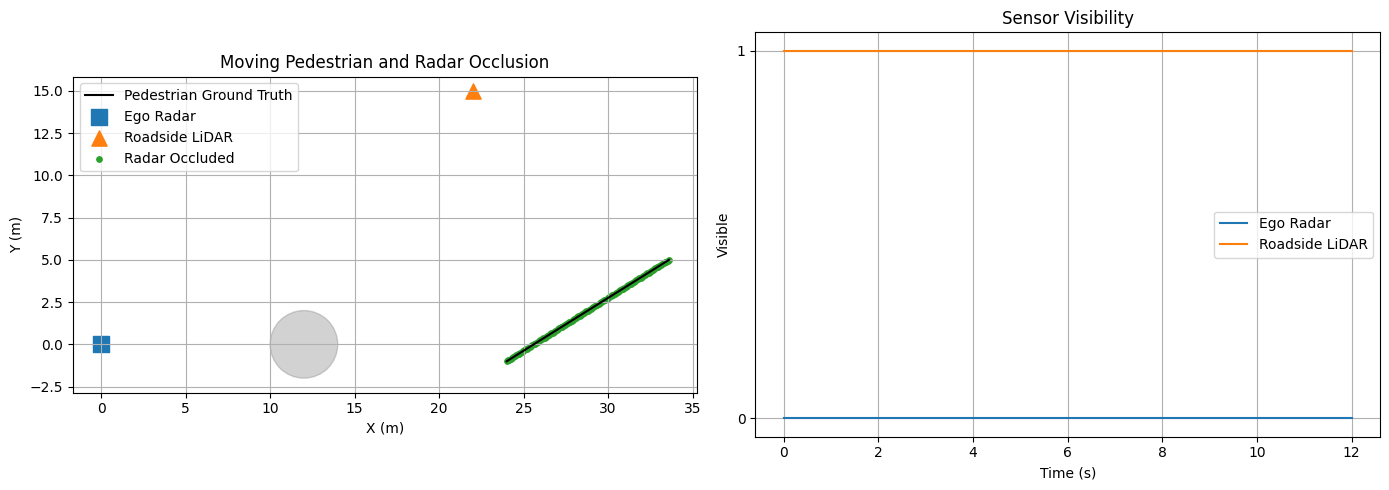

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Urban scenario
dt = 0.1
times = np.arange(0, 12.01, dt)

ego = np.array([0.0, 0.0])
blocker = np.array([12.0, 0.0])
roadside = np.array([22.0, 15.0])

blocker_radius = 2.0

# Moving pedestrian
pedestrian = np.column_stack([
    24.0 + 0.8 * times,
    -1.0 + 0.5 * times
])

def is_occluded(sensor, target, obstacle, radius):
    direction = target - sensor
    denominator = np.dot(direction, direction)

    if denominator < 1e-12:
        return False

    u = np.clip(
        np.dot(obstacle - sensor, direction) / denominator,
        0.0, 1.0
    )

    closest = sensor + u * direction
    distance = np.linalg.norm(closest - obstacle)

    return distance <= radius

radar_visible = []
lidar_visible = []

for position in pedestrian:
    radar_visible.append(
        not is_occluded(
            ego, position, blocker, blocker_radius
        )
    )

    lidar_visible.append(
        not is_occluded(
            roadside, position, blocker, blocker_radius
        )
    )

radar_visible = np.array(radar_visible)
lidar_visible = np.array(lidar_visible)

print("Total frames:", len(times))
print("Radar visible:", radar_visible.sum())
print("LiDAR visible:", lidar_visible.sum())
print(
    "Infrastructure-only:",
    np.sum(~radar_visible & lidar_visible)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Urban geometry
ax = axes[0]
ax.plot(
    pedestrian[:, 0], pedestrian[:, 1],
    "k-", label="Pedestrian Ground Truth"
)
ax.scatter(*ego, s=120, marker="s", label="Ego Radar")
ax.scatter(*roadside, s=120, marker="^",
           label="Roadside LiDAR")

circle = plt.Circle(
    blocker, blocker_radius,
    color="gray", alpha=0.35
)
ax.add_patch(circle)

ax.scatter(
    pedestrian[~radar_visible, 0],
    pedestrian[~radar_visible, 1],
    s=15, label="Radar Occluded"
)

ax.set_aspect("equal")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_title("Moving Pedestrian and Radar Occlusion")
ax.legend()
ax.grid(True)

# Visibility timeline
axes[1].step(
    times, radar_visible.astype(int),
    where="post", label="Ego Radar"
)
axes[1].step(
    times, lidar_visible.astype(int),
    where="post", label="Roadside LiDAR"
)
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Visible")
axes[1].set_yticks([0, 1])
axes[1].set_title("Sensor Visibility")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

=== Cooperative Perception Results ===
Radar detections: 71
V2X packets received: 108
Radar Only             : 0.1659 m
Naive Fusion           : 0.2374 m
Latency-Aware Fusion   : 0.0969 m
Radar Only acquisition: 5.00 s
Naive Fusion acquisition: 0.30 s
Latency-Aware Fusion acquisition: 0.30 s


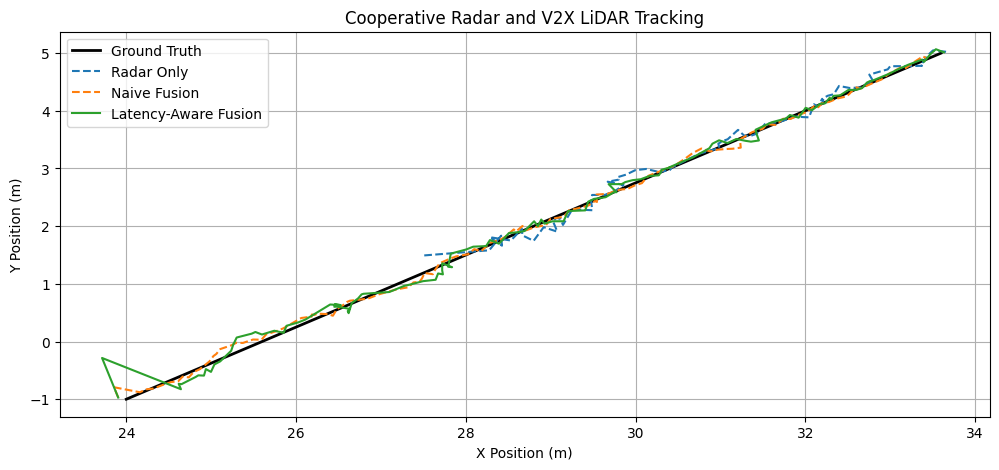

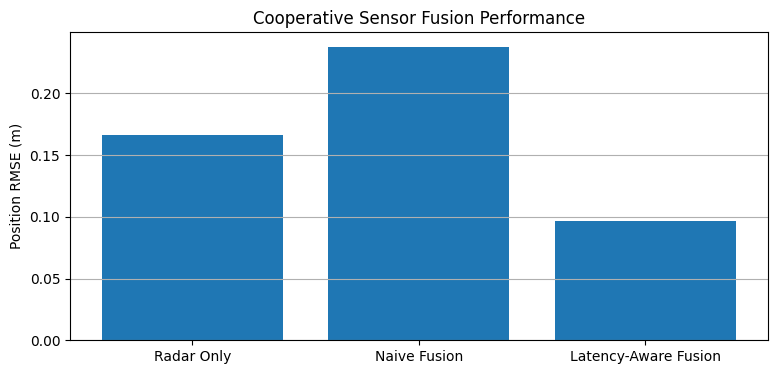

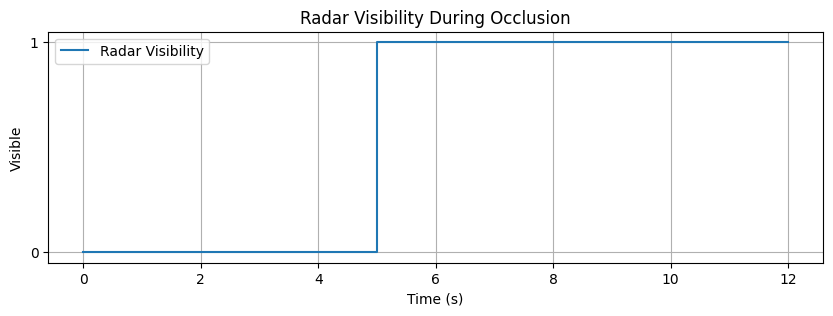

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================
# 1. Urban scenario and sensor settings
# =====================================

rng = np.random.default_rng(2026)

dt = 0.1
times = np.round(np.arange(0, 12.01, dt), 6)

ego = np.array([0.0, 0.0])
roadside = np.array([22.0, 15.0])

truth = np.column_stack([
    24.0 + 0.8 * times,
    -1.0 + 0.5 * times
])

radar_sigma = 0.25
lidar_sigma = 0.12

v2x_latency = 0.3
v2x_loss = 0.10

channel = V2XChannel(
    latency=v2x_latency,
    packet_loss=v2x_loss,
    seed=2026
)

# =====================================
# 2. Generate common sensor observations
# =====================================

radar_events = []
v2x_events = []
radar_mask = []

for i, t in enumerate(times):

    # Blocker moves away from the line of sight at 5 s
    blocker = (
        np.array([12.0, 0.0])
        if t < 5.0
        else np.array([12.0, 8.0])
    )

    radar_visible = not is_occluded(
        ego, truth[i], blocker, 2.0
    )

    lidar_visible = not is_occluded(
        roadside, truth[i], blocker, 2.0
    )

    radar_mask.append(radar_visible)

    if radar_visible:
        z_radar = truth[i] + rng.normal(
            0, radar_sigma, 2
        )
        radar_events.append((
            float(t), float(t),
            z_radar, radar_sigma
        ))

    if lidar_visible:
        z_lidar = truth[i] + rng.normal(
            0, lidar_sigma, 2
        )

        channel.send(V2XMessage(
            timestamp=float(t),
            object_id=1,
            position=z_lidar
        ))

    for msg in channel.receive(float(t) + 1e-8):
        v2x_events.append((
            float(t),
            float(msg.timestamp),
            msg.position.copy(),
            lidar_sigma
        ))

radar_mask = np.asarray(radar_mask)

# =====================================
# 3. Replay KF with received measurements
# =====================================

def run_tracker(current_time, events, latency_aware):

    available = [
        e for e in events
        if e[0] <= current_time + 1e-8
    ]

    if not available:
        return np.full(4, np.nan)

    # Naive: process in arrival order.
    # Aware: process in measurement-time order.
    if latency_aware:
        available.sort(key=lambda e: e[1])
    else:
        available.sort(key=lambda e: e[0])

    first = available[0]
    initial_time = first[1] if latency_aware else first[0]

    kf = CVKalmanFilter(first[2], initial_time)

    # Set uncertainty of the initial measurement
    kf.P[:2, :2] = np.eye(2) * first[3]**2

    for arrival, measured, position, sigma in available[1:]:

        event_time = measured if latency_aware else arrival

        kf.predict(event_time)
        kf.R = np.eye(2) * sigma**2
        kf.update(position)

    kf.predict(current_time)

    return kf.x.copy()


# =====================================
# 4. Run three tracking configurations
# =====================================

all_events = radar_events + v2x_events

radar_only = np.array([
    run_tracker(t, radar_events, False)
    for t in times
])

naive_fusion = np.array([
    run_tracker(t, all_events, False)
    for t in times
])

aware_fusion = np.array([
    run_tracker(t, all_events, True)
    for t in times
])

# =====================================
# 5. Evaluate with common time window
# =====================================

evaluation_mask = times >= 5.0

def calculate_rmse(states):
    valid = (
        evaluation_mask
        & np.isfinite(states[:, 0])
    )

    if not np.any(valid):
        return np.nan

    errors = states[valid, :2] - truth[valid]

    return np.sqrt(
        np.mean(np.sum(errors**2, axis=1))
    )

results = {
    "Radar Only": calculate_rmse(radar_only),
    "Naive Fusion": calculate_rmse(naive_fusion),
    "Latency-Aware Fusion": calculate_rmse(aware_fusion)
}

print("=== Cooperative Perception Results ===")
print("Radar detections:", len(radar_events))
print("V2X packets received:", len(v2x_events))

for name, value in results.items():
    print(f"{name:23s}: {value:.4f} m")

for name, states in [
    ("Radar Only", radar_only),
    ("Naive Fusion", naive_fusion),
    ("Latency-Aware Fusion", aware_fusion)
]:
    valid = np.where(np.isfinite(states[:, 0]))[0]
    acquisition = times[valid[0]] if len(valid) else np.nan
    print(f"{name} acquisition: {acquisition:.2f} s")

# =====================================
# 6. Visualize trajectories
# =====================================

plt.figure(figsize=(12, 5))

plt.plot(
    truth[:, 0], truth[:, 1],
    "k-", linewidth=2, label="Ground Truth"
)

plt.plot(
    radar_only[:, 0], radar_only[:, 1],
    "--", label="Radar Only"
)

plt.plot(
    naive_fusion[:, 0], naive_fusion[:, 1],
    "--", label="Naive Fusion"
)

plt.plot(
    aware_fusion[:, 0], aware_fusion[:, 1],
    "-", label="Latency-Aware Fusion"
)

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("Cooperative Radar and V2X LiDAR Tracking")
plt.legend()
plt.grid(True)
plt.show()

# =====================================
# 7. Compare RMSE
# =====================================

plt.figure(figsize=(9, 4))

plt.bar(
    list(results.keys()),
    list(results.values())
)

plt.ylabel("Position RMSE (m)")
plt.title("Cooperative Sensor Fusion Performance")
plt.grid(axis="y")
plt.show()

# Sensor visibility
plt.figure(figsize=(10, 3))

plt.step(
    times,
    radar_mask.astype(int),
    where="post",
    label="Radar Visibility"
)

plt.xlabel("Time (s)")
plt.ylabel("Visible")
plt.yticks([0, 1])
plt.title("Radar Visibility During Occlusion")
plt.legend()
plt.grid(True)
plt.show()

Radar measurements: 71
Jacobian verification: PASSED


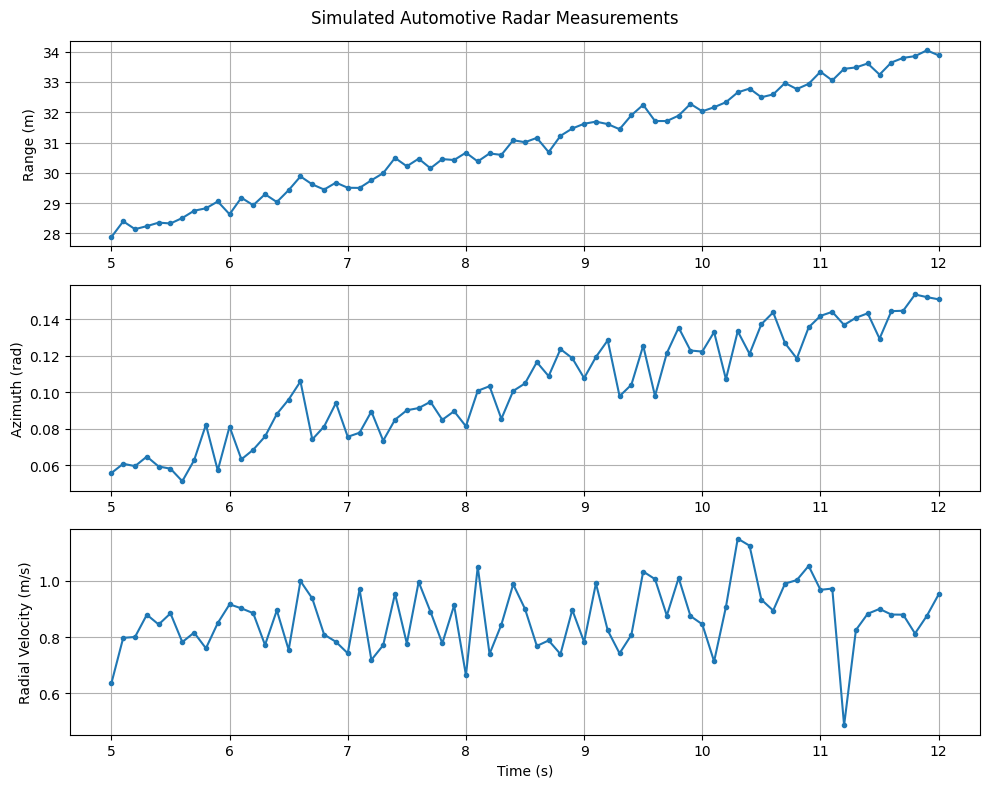

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# State: [px, py, vx, vy]
# Radar position: [0, 0]

def radar_measurement(x):
    px, py, vx, vy = x

    r = np.hypot(px, py)
    if r < 1e-6:
        raise ValueError("Target too close to radar")

    theta = np.arctan2(py, px)
    vr = (px * vx + py * vy) / r

    return np.array([r, theta, vr])


def radar_jacobian(x):
    px, py, vx, vy = x

    r2 = px**2 + py**2
    r = np.sqrt(r2)
    r3 = r2 * r

    if r < 1e-6:
        raise ValueError("Target too close to radar")

    return np.array([
        [px/r, py/r, 0, 0],
        [-py/r2, px/r2, 0, 0],
        [
            vx/r - (px*vx + py*vy)*px/r3,
            vy/r - (px*vx + py*vy)*py/r3,
            px/r,
            py/r
        ]
    ])


def wrap_angle(angle):
    return (angle + np.pi) % (2*np.pi) - np.pi


# Test simulated radar measurements
rng = np.random.default_rng(2026)

radar_noise_std = np.array([
    0.20,               # Range: 20 cm
    np.deg2rad(0.5),   # Azimuth: 0.5 degree
    0.10                # Radial velocity: 0.1 m/s
])

radar_measurements = []
radar_times = []

for i, t in enumerate(times):

    if not radar_mask[i]:
        continue

    state = np.array([
        truth[i, 0],
        truth[i, 1],
        0.8,
        0.5
    ])

    z = radar_measurement(state)
    z_noisy = z + rng.normal(
        0, radar_noise_std
    )

    z_noisy[1] = wrap_angle(z_noisy[1])

    radar_measurements.append(z_noisy)
    radar_times.append(t)

radar_measurements = np.asarray(radar_measurements)
radar_times = np.asarray(radar_times)

print("Radar measurements:", len(radar_measurements))

# Verify analytical Jacobian numerically
x_test = np.array([25., 3., 0.8, 0.5])
eps = 1e-5

J_numeric = np.zeros((3, 4))

for j in range(4):
    offset = np.zeros(4)
    offset[j] = eps

    difference = (
        radar_measurement(x_test + offset)
        - radar_measurement(x_test - offset)
    )
    difference[1] = wrap_angle(difference[1])

    J_numeric[:, j] = difference / (2 * eps)

assert np.allclose(
    radar_jacobian(x_test),
    J_numeric,
    atol=1e-6
)

print("Jacobian verification: PASSED")

fig, axes = plt.subplots(3, 1, figsize=(10, 8))

labels = [
    "Range (m)",
    "Azimuth (rad)",
    "Radial Velocity (m/s)"
]

for j, ax in enumerate(axes):
    ax.plot(radar_times, radar_measurements[:, j], ".-")
    ax.set_ylabel(labels[j])
    ax.grid(True)

axes[-1].set_xlabel("Time (s)")
plt.suptitle("Simulated Automotive Radar Measurements")
plt.tight_layout()
plt.show()

=== NONLINEAR COOPERATIVE EKF ===
Radar EKF              : 0.1442 m
Naive Fusion EKF       : 0.2186 m
Latency-Aware EKF      : 0.0822 m
Radar EKF acquisition: 5.00 s
Naive Fusion EKF acquisition: 0.30 s
Latency-Aware EKF acquisition: 0.30 s


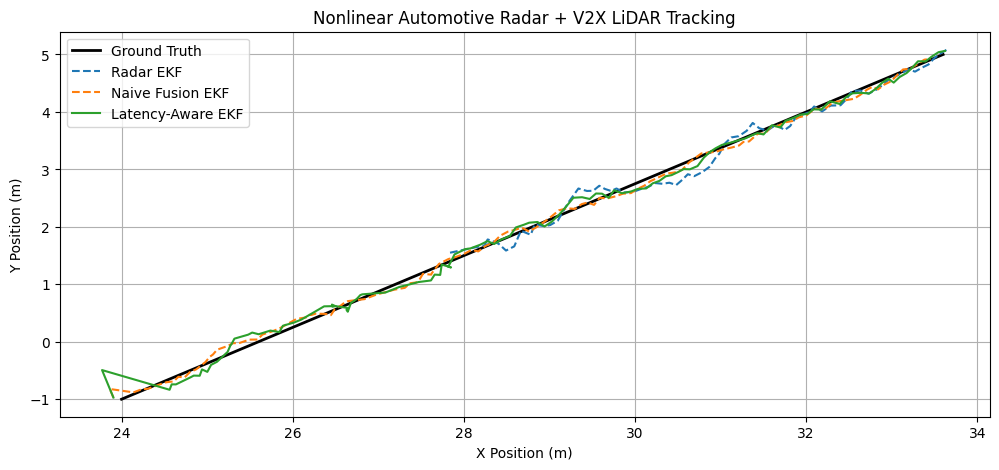

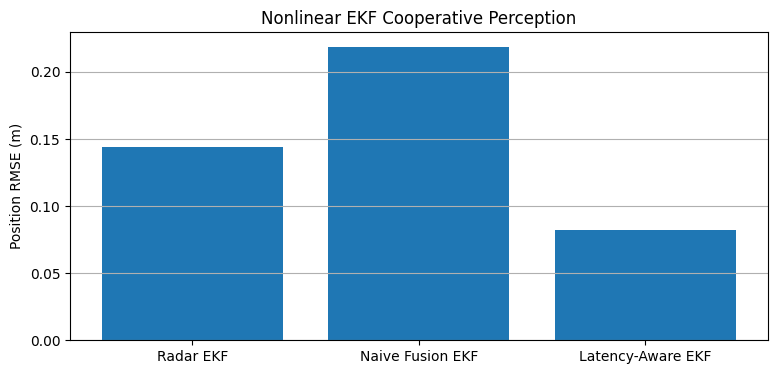

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================
# 1. Nonlinear Radar + LiDAR Extended KF
# ============================================

class CooperativeEKF:

    def __init__(self, position, t, pos_sigma=0.5):
        self.x = np.array([
            position[0], position[1], 0., 0.
        ], dtype=float)

        self.P = np.diag([
            pos_sigma**2, pos_sigma**2, 4., 4.
        ])

        self.t = float(t)
        self.accel_sigma = 0.8

        self.H_lidar = np.array([
            [1., 0., 0., 0.],
            [0., 1., 0., 0.]
        ])

    def predict(self, t):
        dt = float(t - self.t)

        if dt < -1e-8:
            raise ValueError("Out-of-order prediction")

        dt = max(dt, 0.)

        F = np.eye(4)
        F[0, 2] = dt
        F[1, 3] = dt

        G = np.array([
            [0.5*dt**2, 0],
            [0, 0.5*dt**2],
            [dt, 0],
            [0, dt]
        ])

        Q = self.accel_sigma**2 * G @ G.T

        self.x = F @ self.x
        self.P = F @ self.P @ F.T + Q
        self.t = float(t)

    def _correct(self, innovation, H, R):
        S = H @ self.P @ H.T + R
        K = np.linalg.solve(S, H @ self.P).T

        self.x = self.x + K @ innovation

        I = np.eye(4)
        A = I - K @ H

        # Joseph-form covariance update
        self.P = A @ self.P @ A.T + K @ R @ K.T
        self.P = (self.P + self.P.T) / 2

    def update_lidar(self, z, sigma=0.12):
        H = self.H_lidar
        R = np.eye(2) * sigma**2
        innovation = np.asarray(z) - H @ self.x
        self._correct(innovation, H, R)

    def update_radar(self, z):
        H = radar_jacobian(self.x)

        R = np.diag(radar_noise_std**2)

        innovation = np.asarray(z) - radar_measurement(self.x)
        innovation[1] = wrap_angle(innovation[1])

        self._correct(innovation, H, R)


# ============================================
# 2. Assemble sensor events
# ============================================

# Event = (arrival_time, measurement_time, kind, measurement)

radar_ekf_events = [
    (float(t), float(t), "radar", z.copy())
    for t, z in zip(radar_times, radar_measurements)
]

lidar_ekf_events = [
    (float(arrival), float(measured), "lidar", np.asarray(z).copy())
    for arrival, measured, z, sigma in v2x_events
]

# Check that previous cells refer to the same scenario
assert len(times) == len(truth)
assert len(radar_ekf_events) == 71

all_ekf_events = radar_ekf_events + lidar_ekf_events


# ============================================
# 3. Tracking with causal event availability
# ============================================

def ekf_tracking_at(t, events, latency_aware=True):

    available = [
        e for e in events
        if e[0] <= t + 1e-8
    ]

    if not available:
        return np.full(4, np.nan)

    # Timestamp-aware history replay
    available.sort(
        key=lambda e: (e[1] if latency_aware else e[0], e[0])
    )

    first = available[0]
    arrival, measured, kind, z = first

    if kind == "radar":
        r, theta, vr = z
        pos = np.array([
            r*np.cos(theta),
            r*np.sin(theta)
        ])
        pos_sigma = 0.5
    else:
        pos = z[:2]
        pos_sigma = lidar_sigma

    initial_t = measured if latency_aware else arrival

    ekf = CooperativeEKF(pos, initial_t, pos_sigma)

    # Radar radial velocity is also useful for initialization
    if kind == "radar":
        ekf.x[2:] = vr * np.array([
            np.cos(theta), np.sin(theta)
        ])

    for arrival, measured, kind, z in available[1:]:

        event_t = measured if latency_aware else arrival

        ekf.predict(event_t)

        if kind == "radar":
            ekf.update_radar(z)
        else:
            ekf.update_lidar(z, sigma=lidar_sigma)

    ekf.predict(t)

    return ekf.x.copy()


# ============================================
# 4. Run three configurations
# ============================================

radar_ekf = np.array([
    ekf_tracking_at(t, radar_ekf_events)
    for t in times
])

naive_ekf = np.array([
    ekf_tracking_at(t, all_ekf_events, False)
    for t in times
])

cooperative_ekf = np.array([
    ekf_tracking_at(t, all_ekf_events, True)
    for t in times
])


# ============================================
# 5. Compare using a common evaluation window
# ============================================

evaluation_mask = times >= 5.0

def evaluate_ekf(states):
    valid = (
        evaluation_mask
        & np.all(np.isfinite(states[:, :2]), axis=1)
    )

    if not np.any(valid):
        return np.nan

    errors = states[valid, :2] - truth[valid]

    return np.sqrt(np.mean(np.sum(errors**2, axis=1)))


results_ekf = {
    "Radar EKF": evaluate_ekf(radar_ekf),
    "Naive Fusion EKF": evaluate_ekf(naive_ekf),
    "Latency-Aware EKF": evaluate_ekf(cooperative_ekf)
}

print("=== NONLINEAR COOPERATIVE EKF ===")

for name, value in results_ekf.items():
    print(f"{name:23s}: {value:.4f} m")

for name, states in [
    ("Radar EKF", radar_ekf),
    ("Naive Fusion EKF", naive_ekf),
    ("Latency-Aware EKF", cooperative_ekf)
]:
    idx = np.where(np.isfinite(states[:, 0]))[0]
    acquisition = times[idx[0]] if len(idx) else np.nan
    print(f"{name} acquisition: {acquisition:.2f} s")


# ============================================
# 6. Plot trajectory comparison
# ============================================

plt.figure(figsize=(12, 5))

plt.plot(
    truth[:, 0], truth[:, 1],
    "k-", linewidth=2, label="Ground Truth"
)

plt.plot(
    radar_ekf[:, 0], radar_ekf[:, 1],
    "--", label="Radar EKF"
)

plt.plot(
    naive_ekf[:, 0], naive_ekf[:, 1],
    "--", label="Naive Fusion EKF"
)

plt.plot(
    cooperative_ekf[:, 0],
    cooperative_ekf[:, 1],
    "-", label="Latency-Aware EKF"
)

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("Nonlinear Automotive Radar + V2X LiDAR Tracking")
plt.legend()
plt.grid(True)
plt.show()


# ============================================
# 7. RMSE comparison
# ============================================

plt.figure(figsize=(9, 4))

plt.bar(
    list(results_ekf.keys()),
    list(results_ekf.values())
)

plt.ylabel("Position RMSE (m)")
plt.title("Nonlinear EKF Cooperative Perception")
plt.grid(axis="y")
plt.show()

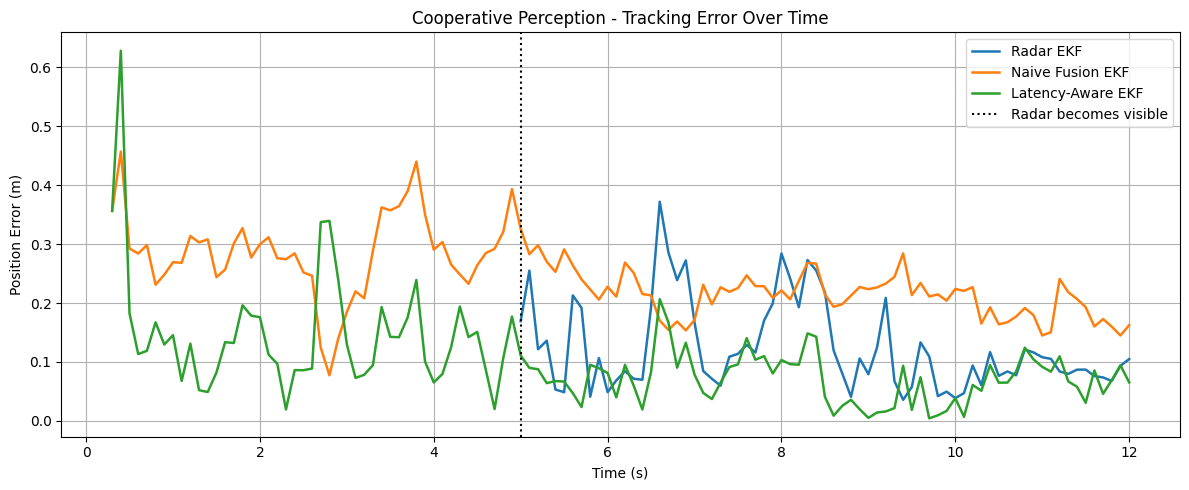

=== TRACK AVAILABILITY ===
Radar EKF               | Availability:  58.7% | First Track: 5.00s
Naive Fusion EKF        | Availability:  97.5% | First Track: 0.30s
Latency-Aware EKF       | Availability:  97.5% | First Track: 0.30s


In [16]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("results", exist_ok=True)

def position_error(states, truth):
    errors = np.full(len(truth), np.nan)
    valid = np.all(np.isfinite(states[:, :2]), axis=1)
    errors[valid] = np.linalg.norm(
        states[valid, :2] - truth[valid], axis=1
    )
    return errors

errors = {
    "Radar EKF": position_error(radar_ekf, truth),
    "Naive Fusion EKF": position_error(naive_ekf, truth),
    "Latency-Aware EKF": position_error(cooperative_ekf, truth)
}

plt.figure(figsize=(12, 5))

for name, err in errors.items():
    plt.plot(times, err, label=name, linewidth=1.8)

plt.axvline(
    5.0, color="black", linestyle=":",
    label="Radar becomes visible"
)

plt.xlabel("Time (s)")
plt.ylabel("Position Error (m)")
plt.title("Cooperative Perception - Tracking Error Over Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("results/tracking_error_v05.png", dpi=200)
plt.show()

# Evaluate track availability
print("=== TRACK AVAILABILITY ===")

for name, states in [
    ("Radar EKF", radar_ekf),
    ("Naive Fusion EKF", naive_ekf),
    ("Latency-Aware EKF", cooperative_ekf)
]:
    valid = np.all(np.isfinite(states[:, :2]), axis=1)
    availability = 100 * valid.mean()
    first_detection = times[np.where(valid)[0][0]] if valid.any() else np.nan

    print(
        f"{name:23s} | "
        f"Availability: {availability:5.1f}% | "
        f"First Track: {first_detection:.2f}s"
    )

=== MONTE CARLO RESULTS ===
Radar Only            : 0.1355 ± 0.0178 m
Naive Fusion          : 0.2211 ± 0.0168 m
Latency-Aware Fusion  : 0.0804 ± 0.0066 m


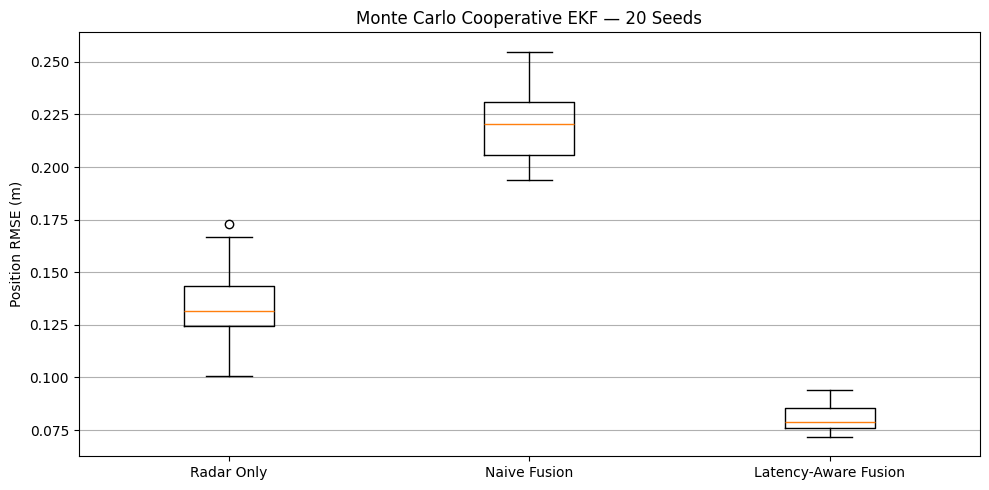

Mean RMSE reduction vs Radar Only: 40.7%


In [17]:
import numpy as np
import matplotlib.pyplot as plt

def run_monte_carlo(seed):
    rng = np.random.default_rng(seed)

    channel = V2XChannel(
        latency=0.3,
        packet_loss=0.10,
        seed=seed + 10000
    )

    radar_events_mc = []
    lidar_events_mc = []

    for i, t in enumerate(times):
        blocker = (
            np.array([12., 0.])
            if t < 5.0
            else np.array([12., 8.])
        )

        radar_visible = not is_occluded(
            ego, truth[i], blocker, 2.0
        )

        lidar_visible = not is_occluded(
            roadside, truth[i], blocker, 2.0
        )

        if radar_visible:
            state = np.array([
                truth[i, 0], truth[i, 1], 0.8, 0.5
            ])
            z = radar_measurement(state)
            z += rng.normal(0, radar_noise_std)
            z[1] = wrap_angle(z[1])

            radar_events_mc.append(
                (float(t), float(t), "radar", z)
            )

        if lidar_visible:
            z = truth[i] + rng.normal(
                0, lidar_sigma, 2
            )
            channel.send(V2XMessage(
                timestamp=float(t),
                object_id=1,
                position=z
            ))

        for msg in channel.receive(float(t) + 1e-8):
            lidar_events_mc.append((
                float(t),
                float(msg.timestamp),
                "lidar",
                msg.position.copy()
            ))

    combined = radar_events_mc + lidar_events_mc

    radar_states = np.array([
        ekf_tracking_at(t, radar_events_mc, True)
        for t in times
    ])

    naive_states = np.array([
        ekf_tracking_at(t, combined, False)
        for t in times
    ])

    aware_states = np.array([
        ekf_tracking_at(t, combined, True)
        for t in times
    ])

    return np.array([
        evaluate_ekf(radar_states),
        evaluate_ekf(naive_states),
        evaluate_ekf(aware_states)
    ])


# Monte Carlo: 20 independent noise realizations
mc_results = np.array([
    run_monte_carlo(seed)
    for seed in range(20)
])

names = [
    "Radar Only",
    "Naive Fusion",
    "Latency-Aware Fusion"
]

print("=== MONTE CARLO RESULTS ===")

for j, name in enumerate(names):
    mean = np.mean(mc_results[:, j])
    std = np.std(mc_results[:, j], ddof=1)

    print(
        f"{name:22s}: "
        f"{mean:.4f} ± {std:.4f} m"
    )

fig, ax = plt.subplots(figsize=(10, 5))

ax.boxplot(
    [mc_results[:, j] for j in range(3)],
    tick_labels=names
)

ax.set_ylabel("Position RMSE (m)")
ax.set_title("Monte Carlo Cooperative EKF — 20 Seeds")
ax.grid(axis="y")

plt.tight_layout()
plt.savefig(
    "results/monte_carlo_v06.png",
    dpi=200
)
plt.show()

improvement = (
    1 - np.mean(mc_results[:, 2])
    / np.mean(mc_results[:, 0])
) * 100

print(
    f"Mean RMSE reduction vs Radar Only: "
    f"{improvement:.1f}%"
)

Total tracks created: 5
Tracks remaining: 3
Total frames: 121


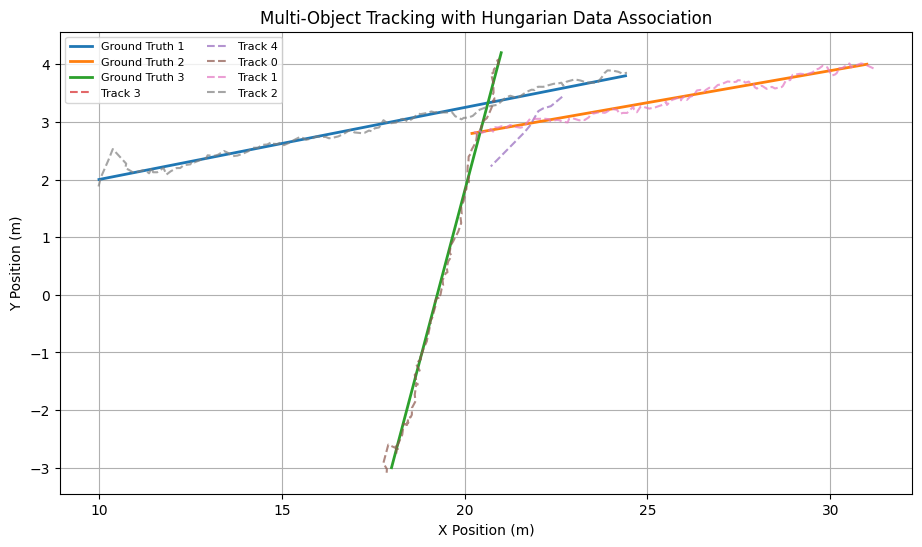

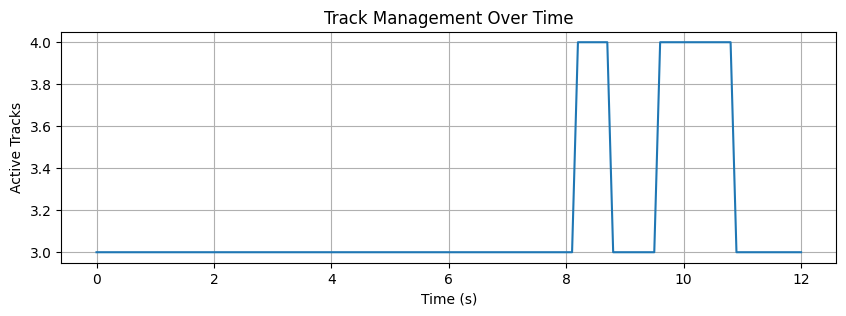

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

rng = np.random.default_rng(2027)
dt = 0.1
T = np.round(np.arange(0, 12.01, dt), 6)

# Three objects: two vehicles and one pedestrian
truth_multi = np.stack([
    np.column_stack((10 + 1.2*T, 2 + 0.15*T)),
    np.column_stack((31 - 0.9*T, 4 - 0.10*T)),
    np.column_stack((18 + 0.25*T, -3 + 0.6*T))
])

# Shape: (3 objects, 121 frames, 2 coordinates)

class Track:
    def __init__(self, z, track_id):
        self.id = track_id
        self.x = np.array([z[0], z[1], 0., 0.])
        self.P = np.diag([0.15**2, 0.15**2, 4., 4.])
        self.misses = 0
        self.hits = 1
        self.history = []

    def predict(self, dt):
        F = np.eye(4)
        F[0, 2] = dt
        F[1, 3] = dt

        G = np.array([
            [dt**2/2, 0],
            [0, dt**2/2],
            [dt, 0],
            [0, dt]
        ])
        self.x = F @ self.x
        self.P = F @ self.P @ F.T + 0.5**2 * G @ G.T
        self.misses += 1

    def update(self, z):
        H = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0]
        ])
        R = np.eye(2) * 0.15**2

        y = z - H @ self.x
        S = H @ self.P @ H.T + R
        K = np.linalg.solve(S, H @ self.P).T

        self.x += K @ y
        A = np.eye(4) - K @ H
        self.P = A @ self.P @ A.T + K @ R @ K.T

        self.misses = 0
        self.hits += 1

    def distance(self, z):
        H = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0]
        ])
        R = np.eye(2) * 0.15**2
        y = z - H @ self.x
        S = H @ self.P @ H.T + R
        return float(y @ np.linalg.solve(S, y))


tracks = []
finished_tracks = []
next_id = 0
track_count = []

for k, t in enumerate(T):

    # Simulated detections, without object IDs
    detections = []

    for obj in range(3):
        if rng.random() < 0.92:
            detections.append(
                truth_multi[obj, k] +
                rng.normal(0, 0.15, size=2)
            )

    # Occasional false alarms
    if rng.random() < 0.03:
        detections.append(
            np.array([
                rng.uniform(8, 32),
                rng.uniform(-5, 6)
            ])
        )

    rng.shuffle(detections)

    for tr in tracks:
        tr.predict(dt)

    # Mahalanobis-distance cost matrix
    n, m = len(tracks), len(detections)
    cost = np.full((n, m), 1e6)

    for i, tr in enumerate(tracks):
        for j, z in enumerate(detections):
            d2 = tr.distance(z)
            if d2 < 9.21:
                cost[i, j] = d2

    assigned_tracks = set()
    assigned_detections = set()

    if n > 0 and m > 0:
        rows, cols = linear_sum_assignment(cost)

        for i, j in zip(rows, cols):
            if cost[i, j] < 9.21:
                tracks[i].update(detections[j])
                assigned_tracks.add(i)
                assigned_detections.add(j)

    # Start new tracks for unassigned detections
    for j, z in enumerate(detections):
        if j not in assigned_detections:
            tracks.append(Track(z, next_id))
            next_id += 1

    # Store state estimates
    for tr in tracks:
        tr.history.append(
            (float(t), tr.x[0], tr.x[1])
        )

    # Delete tracks after 5 consecutive misses
    survivors = []
    for tr in tracks:
        if tr.misses > 5:
            finished_tracks.append(tr)
        else:
            survivors.append(tr)

    tracks = survivors
    track_count.append(len(tracks))

all_tracks = finished_tracks + tracks

print("Total tracks created:", next_id)
print("Tracks remaining:", len(tracks))
print("Total frames:", len(T))

# Visualization
plt.figure(figsize=(11, 6))

for i in range(3):
    plt.plot(
        truth_multi[i, :, 0],
        truth_multi[i, :, 1],
        linewidth=2,
        label=f"Ground Truth {i+1}"
    )

for tr in all_tracks:
    if len(tr.history) >= 3:
        h = np.array(tr.history)
        plt.plot(
            h[:, 1], h[:, 2],
            "--", alpha=0.7,
            label=f"Track {tr.id}"
        )

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("Multi-Object Tracking with Hungarian Data Association")
plt.grid(True)
plt.legend(fontsize=8, ncol=2)
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(T, track_count)
plt.xlabel("Time (s)")
plt.ylabel("Active Tracks")
plt.title("Track Management Over Time")
plt.grid(True)
plt.show()

=== TRACK MANAGEMENT v0.8 ===
Total tracks created: 5
Confirmed tracks: 4
Active confirmed tracks: 3


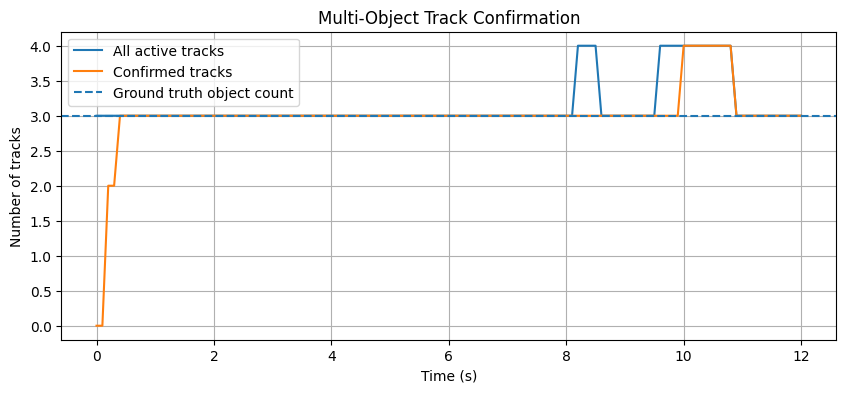

In [19]:
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

class ConfirmedTrack(Track):
    def __init__(self, z, track_id):
        super().__init__(z, track_id)
        self.status = "tentative"
        self.age = 1
        self.hit_window = deque([1], maxlen=5)

    def predict(self, dt):
        super().predict(dt)
        self.age += 1
        self.hit_window.append(0)

    def update(self, z):
        super().update(z)
        self.hit_window[-1] = 1

        if sum(self.hit_window) >= 3:
            self.status = "confirmed"


rng = np.random.default_rng(2027)

tracks_v08 = []
finished_v08 = []
next_id_v08 = 0

confirmed_counts = []
total_counts = []

for k, t in enumerate(T):

    detections = []

    # Generate unlabeled observations
    for obj in range(3):
        if rng.random() < 0.92:
            z = (
                truth_multi[obj, k]
                + rng.normal(0, 0.15, 2)
            )
            detections.append(z)

    # False alarm
    if rng.random() < 0.03:
        detections.append(np.array([
            rng.uniform(8, 32),
            rng.uniform(-5, 6)
        ]))

    rng.shuffle(detections)

    for tr in tracks_v08:
        tr.predict(0.1)

    n = len(tracks_v08)
    m = len(detections)

    cost = np.full((n, m), 1e6)

    for i, tr in enumerate(tracks_v08):
        for j, z in enumerate(detections):
            d2 = tr.distance(z)
            if d2 <= 9.21:
                cost[i, j] = d2

    assigned_detections = set()

    if n and m:
        rows, cols = linear_sum_assignment(cost)

        for i, j in zip(rows, cols):
            if cost[i, j] <= 9.21:
                tracks_v08[i].update(detections[j])
                assigned_detections.add(j)

    for j, z in enumerate(detections):
        if j not in assigned_detections:
            tracks_v08.append(
                ConfirmedTrack(z, next_id_v08)
            )
            next_id_v08 += 1

    survivors = []

    for tr in tracks_v08:

        tr.history.append((
            float(t),
            tr.x[0],
            tr.x[1],
            tr.status
        ))

        # Tentative tracks must reach 3 hits
        # within their first 5 frames.
        if tr.status == "tentative" and tr.age >= 5:
            finished_v08.append(tr)
            continue

        # Delete confirmed tracks after 5 misses
        if tr.status == "confirmed" and tr.misses > 5:
            finished_v08.append(tr)
            continue

        survivors.append(tr)

    tracks_v08 = survivors

    confirmed_counts.append(sum(
        tr.status == "confirmed"
        for tr in tracks_v08
    ))

    total_counts.append(len(tracks_v08))


all_v08 = finished_v08 + tracks_v08

print("=== TRACK MANAGEMENT v0.8 ===")
print("Total tracks created:", next_id_v08)
print("Confirmed tracks:", sum(
    tr.status == "confirmed" for tr in all_v08
))
print("Active confirmed tracks:", confirmed_counts[-1])

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(T, total_counts, label="All active tracks")
ax.plot(T, confirmed_counts, label="Confirmed tracks")

ax.axhline(
    3, linestyle="--",
    label="Ground truth object count"
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Number of tracks")
ax.set_title("Multi-Object Track Confirmation")
ax.legend()
ax.grid(True)

plt.show()

=== CONFIRMED TRACK DIAGNOSTICS ===
Track 0: confirmed from 0.2s to 12.0s | Mean nearest-GT distance = 0.087 m
Track 1: confirmed from 0.4s to 12.0s | Mean nearest-GT distance = 0.084 m
Track 2: confirmed from 0.2s to 12.0s | Mean nearest-GT distance = 0.098 m
Track 3: never confirmed
Track 4: confirmed from 10.0s to 10.9s | Mean nearest-GT distance = 0.412 m


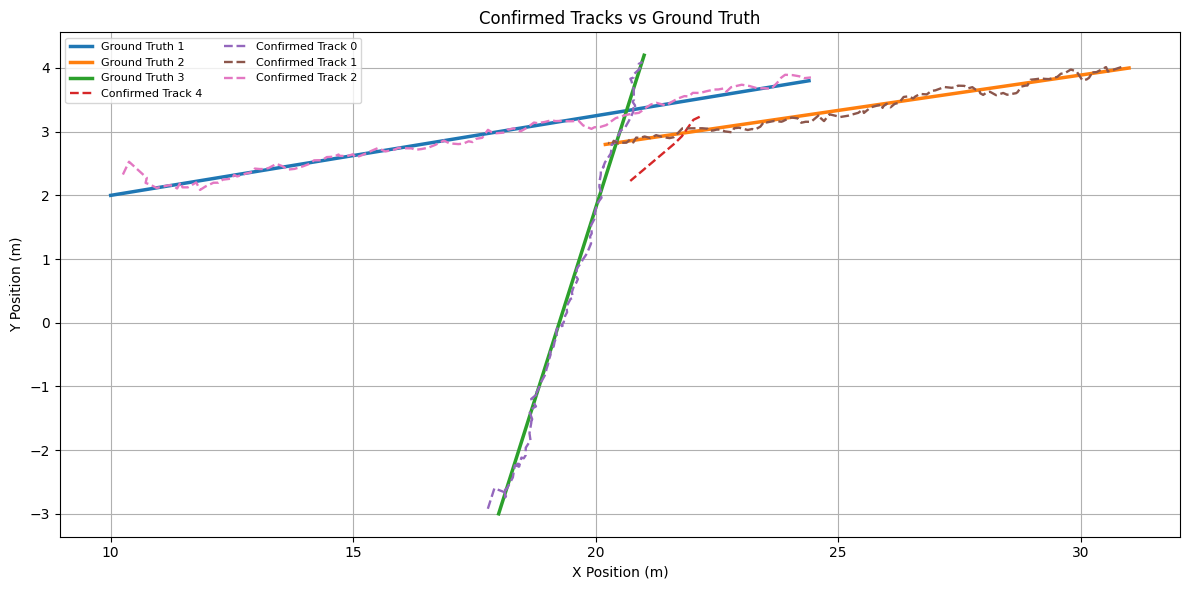

In [20]:
import numpy as np
import matplotlib.pyplot as plt

print("=== CONFIRMED TRACK DIAGNOSTICS ===")

for tr in sorted(all_v08, key=lambda x: x.id):

    confirmed_history = [
        h for h in tr.history
        if h[3] == "confirmed"
    ]

    if not confirmed_history:
        print(f"Track {tr.id}: never confirmed")
        continue

    start = confirmed_history[0][0]
    end = confirmed_history[-1][0]

    distances = []

    for t, x, y, status in confirmed_history:

        k = int(np.argmin(np.abs(T - t)))

        d = np.linalg.norm(
            truth_multi[:, k, :] - np.array([x, y]),
            axis=1
        )

        distances.append(d)

    distances = np.array(distances)

    print(
        f"Track {tr.id}: "
        f"confirmed from {start:.1f}s to {end:.1f}s | "
        f"Mean nearest-GT distance = "
        f"{distances.min(axis=1).mean():.3f} m"
    )

# Plot every confirmed track against ground truth
plt.figure(figsize=(12, 6))

for i in range(3):
    plt.plot(
        truth_multi[i, :, 0],
        truth_multi[i, :, 1],
        linewidth=2.5,
        label=f"Ground Truth {i+1}"
    )

for tr in all_v08:

    h = np.array([
        [t, x, y]
        for t, x, y, status in tr.history
        if status == "confirmed"
    ])

    if len(h):
        plt.plot(
            h[:, 1], h[:, 2],
            "--",
            linewidth=1.7,
            label=f"Confirmed Track {tr.id}"
        )

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("Confirmed Tracks vs Ground Truth")
plt.legend(fontsize=8, ncol=2)
plt.grid(True)
plt.tight_layout()
plt.show()

=== MULTI-OBJECT TRACK EVALUATION ===
Track 3: {'matched': 0, 'unmatched': 0, 'near_existing': 0}
Track 4: {'matched': 1, 'unmatched': 9, 'near_existing': 8}
Track 0: {'matched': 119, 'unmatched': 0, 'near_existing': 0}
Track 1: {'matched': 116, 'unmatched': 1, 'near_existing': 1}
Track 2: {'matched': 119, 'unmatched': 0, 'near_existing': 0}

Total unmatched confirmed track-frames: 10
Total missed GT object-frames: 8


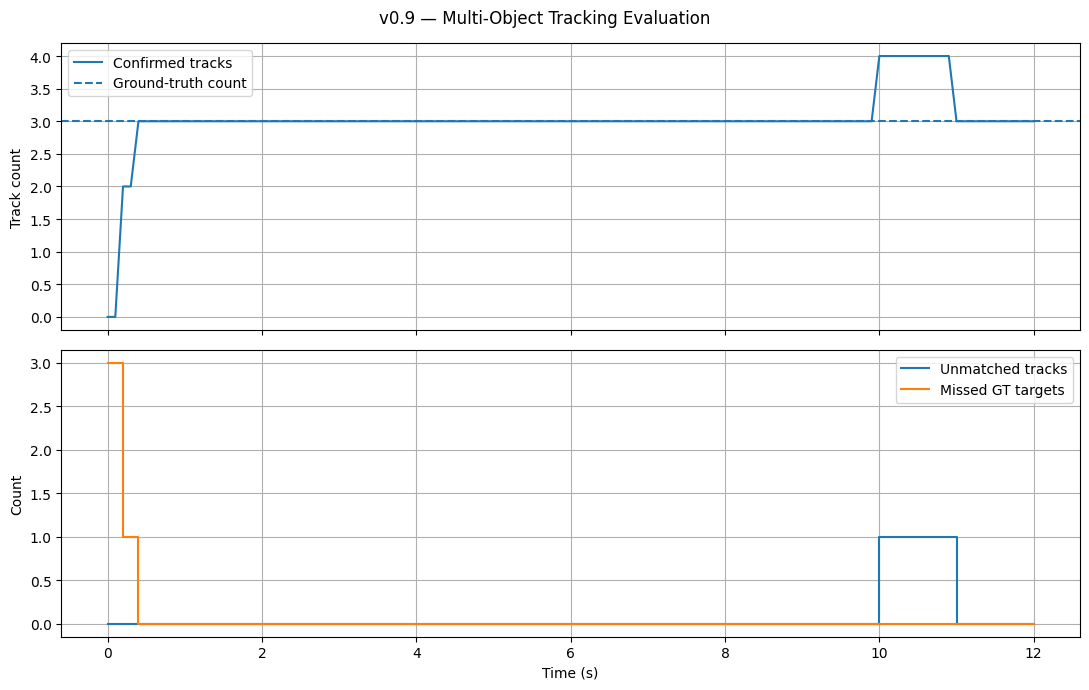

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

# Evaluation settings
MATCH_THRESHOLD = 0.75  # meters
DUPLICATE_THRESHOLD = 0.75  # meters

evaluation = []
track_diagnostics = {}

for tr in all_v08:
    track_diagnostics[tr.id] = {
        "matched": 0,
        "unmatched": 0,
        "near_existing": 0
    }

for k, t in enumerate(T):

    active = []

    for tr in all_v08:
        for h in tr.history:
            if abs(h[0] - t) < 1e-6 and h[3] == "confirmed":
                active.append((tr.id, np.array(h[1:3])))
                break

    gt = truth_multi[:, k, :]
    n_tracks = len(active)

    if n_tracks == 0:
        evaluation.append((t, 0, 0, len(gt), 0))
        continue

    positions = np.array([a[1] for a in active])

    distances = np.linalg.norm(
        positions[:, None, :] - gt[None, :, :],
        axis=2
    )

    # One-to-one assignment, with a distance threshold
    n_gt = len(gt)
    size = n_tracks + n_gt
    penalty = MATCH_THRESHOLD + 1.0

    cost = np.full((size, size), 0.0)
    cost[:n_tracks, :n_gt] = np.where(
        distances <= MATCH_THRESHOLD,
        distances,
        2 * penalty
    )
    cost[:n_tracks, n_gt:] = penalty
    cost[n_tracks:, :n_gt] = penalty

    rows, cols = linear_sum_assignment(cost)

    matched_indices = set()

    for i, j in zip(rows, cols):
        if (
            i < n_tracks
            and j < n_gt
            and distances[i, j] <= MATCH_THRESHOLD
        ):
            matched_indices.add(i)
            track_diagnostics[active[i][0]]["matched"] += 1

    for i, (track_id, position) in enumerate(active):

        if i not in matched_indices:
            track_diagnostics[track_id]["unmatched"] += 1

            other_positions = [
                active[j][1]
                for j in matched_indices
            ]

            if other_positions:
                nearest_track = min(
                    np.linalg.norm(position - p)
                    for p in other_positions
                )

                if nearest_track < DUPLICATE_THRESHOLD:
                    track_diagnostics[track_id]["near_existing"] += 1

    matched = len(matched_indices)
    false_count = n_tracks - matched
    missed_count = len(gt) - matched

    evaluation.append((
        t, n_tracks, false_count, missed_count, matched
    ))

evaluation = np.array(evaluation)

print("=== MULTI-OBJECT TRACK EVALUATION ===")

for track_id, stats in track_diagnostics.items():
    print(f"Track {track_id}: {stats}")

print("\nTotal unmatched confirmed track-frames:",
      int(evaluation[:, 2].sum()))

print("Total missed GT object-frames:",
      int(evaluation[:, 3].sum()))

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(
    evaluation[:, 0],
    evaluation[:, 1],
    label="Confirmed tracks"
)
axes[0].axhline(
    3, linestyle="--",
    label="Ground-truth count"
)
axes[0].set_ylabel("Track count")
axes[0].legend()
axes[0].grid(True)

axes[1].step(
    evaluation[:, 0],
    evaluation[:, 2],
    where="post",
    label="Unmatched tracks"
)
axes[1].step(
    evaluation[:, 0],
    evaluation[:, 3],
    where="post",
    label="Missed GT targets"
)

axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Count")
axes[1].legend()
axes[1].grid(True)

plt.suptitle("v0.9 — Multi-Object Tracking Evaluation")
plt.tight_layout()
plt.show()

=== DUPLICATE CANDIDATE ANALYSIS ===
Track pair (0, 1): 1 suspicious overlapping frames
Track pair (1, 4): 3 suspicious overlapping frames


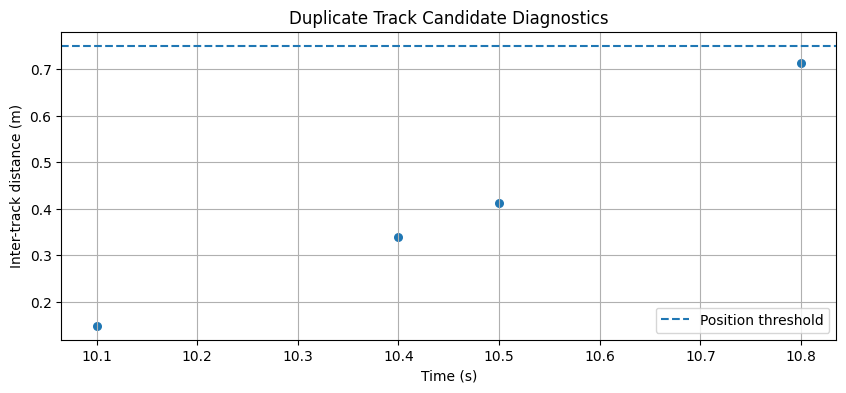

In [22]:

import numpy as np
import matplotlib.pyplot as plt

POSITION_THRESHOLD = 0.75   # meters
VELOCITY_THRESHOLD = 1.0   # m/s

duplicate_candidates = []
duplicate_flags = {}
diagnostics = []

for k, t in enumerate(T):
    active = []

    for tr in all_v08:
        matches = [
            h for h in tr.history
            if abs(h[0] - t) < 1e-6
            and h[3] == "confirmed"
        ]

        if matches:
            active.append((tr.id, np.array(matches[0][1:3])))

    # Estimate velocity using historical positions
    for i in range(len(active)):
        for j in range(i + 1, len(active)):
            id_a, p_a = active[i]
            id_b, p_b = active[j]

            distance = np.linalg.norm(p_a - p_b)

            def velocity_at(track_id, current_time):
                tr = next(
                    tr for tr in all_v08 if tr.id == track_id
                )
                h = [
                    row for row in tr.history
                    if row[0] <= current_time + 1e-6
                ]
                if len(h) < 2:
                    return None

                a, b = h[-2], h[-1]
                delta = b[0] - a[0]
                if delta <= 0:
                    return None

                return (
                    np.array(b[1:3]) -
                    np.array(a[1:3])
                ) / delta

            va = velocity_at(id_a, t)
            vb = velocity_at(id_b, t)

            if va is None or vb is None:
                continue

            velocity_difference = np.linalg.norm(va - vb)

            if (distance < POSITION_THRESHOLD
                    and velocity_difference < VELOCITY_THRESHOLD):

                pair = tuple(sorted((id_a, id_b)))
                duplicate_flags[pair] = duplicate_flags.get(pair, 0) + 1

                diagnostics.append(
                    (t, id_a, id_b, distance, velocity_difference)
                )

print("=== DUPLICATE CANDIDATE ANALYSIS ===")

for pair, count in sorted(duplicate_flags.items()):
    print(
        f"Track pair {pair}: "
        f"{count} suspicious overlapping frames"
    )

if not duplicate_flags:
    print("No duplicate candidates under current thresholds.")

if diagnostics:
    data = np.array(diagnostics)

    plt.figure(figsize=(10, 4))
    plt.scatter(data[:, 0], data[:, 3], s=30)
    plt.axhline(
        POSITION_THRESHOLD,
        linestyle="--",
        label="Position threshold"
    )
    plt.xlabel("Time (s)")
    plt.ylabel("Inter-track distance (m)")
    plt.title("Duplicate Track Candidate Diagnostics")
    plt.grid(True)
    plt.legend()
    plt.show()


=== TRACK BIRTH SUPPRESSION ===
Baseline tracks created: 5
Improved tracks created: 5
Suppressed births: 0
Final confirmed tracks: 3
Maximum confirmed tracks: 4


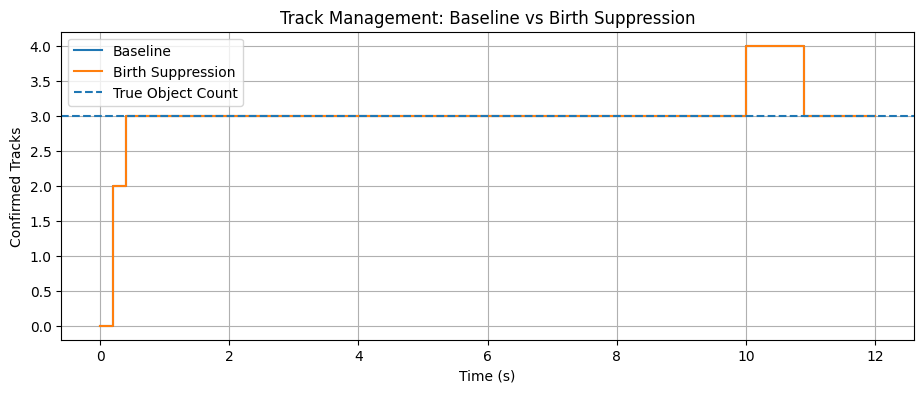

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

def run_tracker_v11(seed=2027, suppress_birth=True):
    rng = np.random.default_rng(seed)
    tracks = []
    finished = []
    next_id = 0

    all_counts = []
    confirmed_counts = []
    suppressed = 0

    H = np.array([
        [1., 0., 0., 0.],
        [0., 1., 0., 0.]
    ])
    R = np.eye(2) * 0.15**2

    for k, t in enumerate(T):
        detections = []

        for obj in range(3):
            if rng.random() < 0.92:
                detections.append(
                    truth_multi[obj, k] +
                    rng.normal(0, 0.15, 2)
                )

        if rng.random() < 0.03:
            detections.append(np.array([
                rng.uniform(8, 32),
                rng.uniform(-5, 6)
            ]))

        rng.shuffle(detections)

        for tr in tracks:
            tr.predict(0.1)

        n, m = len(tracks), len(detections)
        cost = np.full((n, m), 1e6)

        for i, tr in enumerate(tracks):
            for j, z in enumerate(detections):
                d2 = tr.distance(z)
                if d2 <= 9.21:
                    cost[i, j] = d2

        assigned = set()

        if n and m:
            rows, cols = linear_sum_assignment(cost)

            for i, j in zip(rows, cols):
                if cost[i, j] <= 9.21:
                    tracks[i].update(detections[j])
                    assigned.add(j)

        # Birth suppression for unassigned detections
        for j, z in enumerate(detections):
            if j in assigned:
                continue

            duplicate_candidate = False

            if suppress_birth:
                for tr in tracks:
                    if tr.status != "confirmed":
                        continue

                    innovation = z - H @ tr.x
                    S = H @ tr.P @ H.T + R

                    d2 = float(
                        innovation @ np.linalg.solve(
                            S, innovation
                        )
                    )

                    distance = np.linalg.norm(innovation)

                    if d2 < 5.99 and distance < 0.8:
                        duplicate_candidate = True
                        suppressed += 1
                        break

            if not duplicate_candidate:
                tracks.append(
                    ConfirmedTrack(z, next_id)
                )
                next_id += 1

        survivors = []

        for tr in tracks:
            tr.history.append((
                float(t),
                tr.x[0],
                tr.x[1],
                tr.status
            ))

            if tr.status == "tentative" and tr.age >= 5:
                finished.append(tr)
            elif tr.status == "confirmed" and tr.misses > 5:
                finished.append(tr)
            else:
                survivors.append(tr)

        tracks = survivors

        all_counts.append(len(tracks))
        confirmed_counts.append(sum(
            tr.status == "confirmed"
            for tr in tracks
        ))

    return {
        "created": next_id,
        "suppressed": suppressed,
        "tracks": finished + tracks,
        "all_counts": np.array(all_counts),
        "confirmed_counts": np.array(confirmed_counts)
    }


# Compare original versus new birth policy
baseline = run_tracker_v11(suppress_birth=False)
improved = run_tracker_v11(suppress_birth=True)

print("=== TRACK BIRTH SUPPRESSION ===")

print("Baseline tracks created:", baseline["created"])
print("Improved tracks created:", improved["created"])
print("Suppressed births:", improved["suppressed"])

print(
    "Final confirmed tracks:",
    improved["confirmed_counts"][-1]
)

print(
    "Maximum confirmed tracks:",
    improved["confirmed_counts"].max()
)

plt.figure(figsize=(11, 4))

plt.step(
    T,
    baseline["confirmed_counts"],
    where="post",
    label="Baseline"
)

plt.step(
    T,
    improved["confirmed_counts"],
    where="post",
    label="Birth Suppression"
)

plt.axhline(
    3,
    linestyle="--",
    label="True Object Count"
)

plt.xlabel("Time (s)")
plt.ylabel("Confirmed Tracks")
plt.title("Track Management: Baseline vs Birth Suppression")
plt.grid(True)
plt.legend()
plt.show()

In [24]:

import numpy as np
from scipy.optimize import linear_sum_assignment

def diagnose_track_birth(seed=2027):
    rng = np.random.default_rng(seed)
    active = []
    next_id = 0
    birth_log = []

    for k, t in enumerate(T):
        detections = []

        for obj in range(3):
            if rng.random() < 0.92:
                detections.append(
                    truth_multi[obj, k] +
                    rng.normal(0, 0.15, 2)
                )

        if rng.random() < 0.03:
            detections.append(np.array([
                rng.uniform(8, 32),
                rng.uniform(-5, 6)
            ]))

        rng.shuffle(detections)

        for tr in active:
            tr.predict(0.1)

        n, m = len(active), len(detections)
        cost = np.full((n, m), 1e6)

        for i, tr in enumerate(active):
            for j, z in enumerate(detections):
                cost[i, j] = tr.distance(z)

        assigned = set()

        if n and m:
            rows, cols = linear_sum_assignment(cost)

            for i, j in zip(rows, cols):
                if cost[i, j] <= 9.21:
                    active[i].update(detections[j])
                    assigned.add(j)

        for j, z in enumerate(detections):
            if j in assigned:
                continue

            nearest = None

            if active:
                nearest = min(
                    active,
                    key=lambda tr: np.linalg.norm(
                        tr.x[:2] - z
                    )
                )

            nearest_distance = (
                np.linalg.norm(nearest.x[:2] - z)
                if nearest is not None else np.nan
            )

            nearest_d2 = (
                nearest.distance(z)
                if nearest is not None else np.nan
            )

            birth_log.append({
                "time": float(t),
                "new_id": next_id,
                "nearest_id": (
                    nearest.id if nearest else None
                ),
                "distance_m": nearest_distance,
                "mahalanobis_d2": nearest_d2
            })

            active.append(ConfirmedTrack(z, next_id))
            next_id += 1

        survivors = []

        for tr in active:
            if tr.status == "tentative" and tr.age >= 5:
                continue
            if tr.status == "confirmed" and tr.misses > 5:
                continue
            survivors.append(tr)

        active = survivors

    return birth_log


birth_log = diagnose_track_birth()

print("=== TRACK BIRTH DIAGNOSTICS ===")

for item in birth_log:
    print(
        f"t={item['time']:.1f}s | "
        f"New Track={item['new_id']} | "
        f"Nearest Track={item['nearest_id']} | "
        f"Distance={item['distance_m']:.3f}m | "
        f"Mahalanobis d²={item['mahalanobis_d2']:.2f}"
    )


=== TRACK BIRTH DIAGNOSTICS ===
t=0.0s | New Track=0 | Nearest Track=None | Distance=nanm | Mahalanobis d²=nan
t=0.0s | New Track=1 | Nearest Track=0 | Distance=15.049m | Mahalanobis d²=5032.91
t=0.0s | New Track=2 | Nearest Track=0 | Distance=9.315m | Mahalanobis d²=1928.14
t=8.2s | New Track=3 | Nearest Track=0 | Distance=6.416m | Mahalanobis d²=1469.23
t=9.6s | New Track=4 | Nearest Track=1 | Distance=0.531m | Mahalanobis d²=9.63


=== BIRTH EXCLUSION EXPERIMENT ===
Gate=0.0m | Created=5 | Suppressed=0 | Max Confirmed=4 | Final Confirmed=3
Gate=0.4m | Created=5 | Suppressed=0 | Max Confirmed=4 | Final Confirmed=3
Gate=0.6m | Created=4 | Suppressed=1 | Max Confirmed=3 | Final Confirmed=3
Gate=0.8m | Created=4 | Suppressed=1 | Max Confirmed=3 | Final Confirmed=3


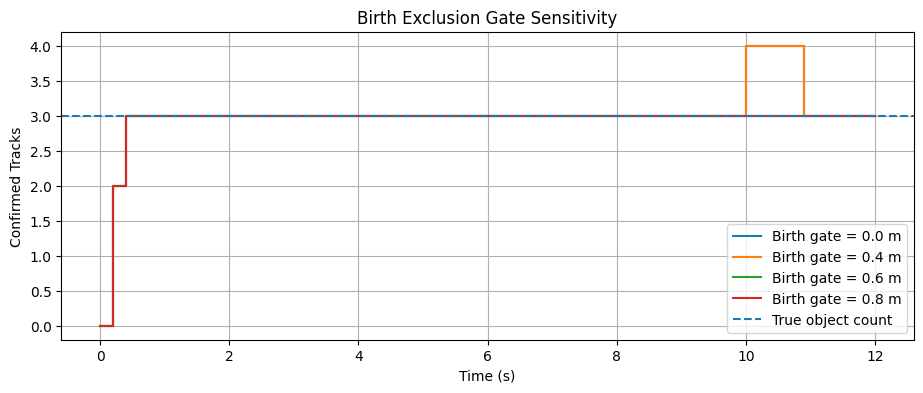

In [25]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

def run_tracker_v13(seed=2027, birth_gate=0.0):
    rng = np.random.default_rng(seed)
    active, finished = [], []
    next_id = 0
    suppressed = 0
    confirmed_counts = []

    for k, t in enumerate(T):
        detections = []

        for obj in range(3):
            if rng.random() < 0.92:
                detections.append(
                    truth_multi[obj, k] +
                    rng.normal(0, 0.15, 2)
                )

        if rng.random() < 0.03:
            detections.append(np.array([
                rng.uniform(8, 32),
                rng.uniform(-5, 6)
            ]))

        rng.shuffle(detections)

        for tr in active:
            tr.predict(0.1)

        n, m = len(active), len(detections)
        cost = np.full((n, m), 1e6)

        for i, tr in enumerate(active):
            for j, z in enumerate(detections):
                d2 = tr.distance(z)
                if d2 <= 9.21:
                    cost[i, j] = d2

        assigned = set()

        if n and m:
            rows, cols = linear_sum_assignment(cost)
            for i, j in zip(rows, cols):
                if cost[i, j] <= 9.21:
                    active[i].update(detections[j])
                    assigned.add(j)

        for j, z in enumerate(detections):
            if j in assigned:
                continue

            # Birth exclusion: do not create a new track
            # close to an already confirmed track.
            exclude = False

            if birth_gate > 0:
                for tr in active:
                    if tr.status != "confirmed":
                        continue

                    distance = np.linalg.norm(
                        z - tr.x[:2]
                    )

                    if distance < birth_gate:
                        exclude = True
                        suppressed += 1
                        break

            if not exclude:
                active.append(ConfirmedTrack(z, next_id))
                next_id += 1

        survivors = []

        for tr in active:
            tr.history.append((
                float(t), tr.x[0], tr.x[1], tr.status
            ))

            if tr.status == "tentative" and tr.age >= 5:
                finished.append(tr)
            elif tr.status == "confirmed" and tr.misses > 5:
                finished.append(tr)
            else:
                survivors.append(tr)

        active = survivors

        confirmed_counts.append(sum(
            tr.status == "confirmed"
            for tr in active
        ))

    return {
        "created": next_id,
        "suppressed": suppressed,
        "confirmed_counts": np.array(confirmed_counts),
        "tracks": finished + active
    }


gates = [0.0, 0.4, 0.6, 0.8]
outputs = {}

for gate in gates:
    outputs[gate] = run_tracker_v13(
        seed=2027,
        birth_gate=gate
    )

print("=== BIRTH EXCLUSION EXPERIMENT ===")
for gate, result in outputs.items():
    print(
        f"Gate={gate:.1f}m | "
        f"Created={result['created']} | "
        f"Suppressed={result['suppressed']} | "
        f"Max Confirmed={result['confirmed_counts'].max()} | "
        f"Final Confirmed={result['confirmed_counts'][-1]}"
    )

plt.figure(figsize=(11, 4))

for gate, result in outputs.items():
    plt.step(
        T,
        result["confirmed_counts"],
        where="post",
        label=f"Birth gate = {gate:.1f} m"
    )

plt.axhline(
    3,
    linestyle="--",
    label="True object count"
)

plt.xlabel("Time (s)")
plt.ylabel("Confirmed Tracks")
plt.title("Birth Exclusion Gate Sensitivity")
plt.legend()
plt.grid(True)
plt.show()


=== TRACK MANAGEMENT VALIDATION ===

Birth Gate: 0.0 m
Runs with excess tracks: 44/50
Mean tracks created: 9.02
Mean excess-track frames: 15.18
Mean count-error frames: 18.08

Birth Gate: 0.8 m
Runs with excess tracks: 3/50
Mean tracks created: 6.68
Mean excess-track frames: 0.76
Mean count-error frames: 3.66


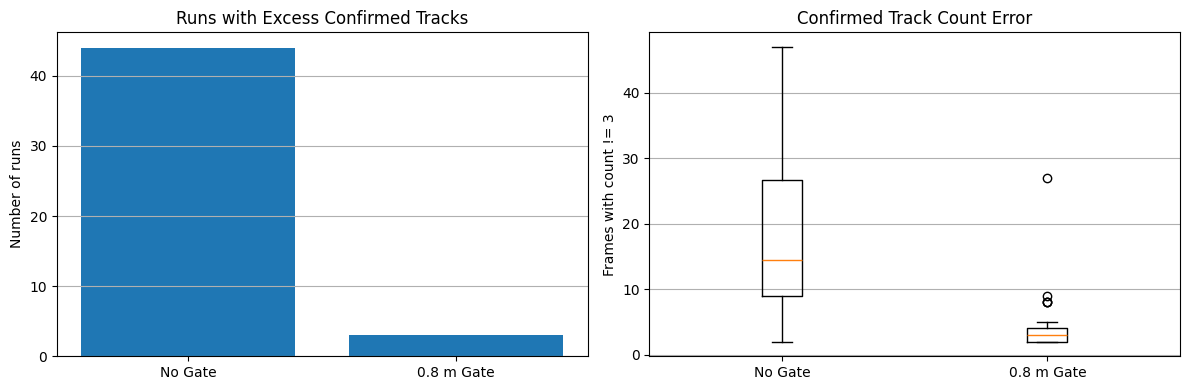

In [26]:

import numpy as np
import matplotlib.pyplot as plt

seeds = range(50)
gates = [0.0, 0.8]

validation = {}

for gate in gates:
    records = []

    for seed in seeds:
        result = run_tracker_v13(
            seed=seed,
            birth_gate=gate
        )

        counts = result["confirmed_counts"]

        records.append({
            "created": result["created"],
            "suppressed": result["suppressed"],
            "max_confirmed": counts.max(),
            "final_confirmed": counts[-1],
            "excess_frames": np.sum(counts > 3),
            "count_error_frames": np.sum(counts != 3)
        })

    validation[gate] = records

print("=== TRACK MANAGEMENT VALIDATION ===")

for gate in gates:
    records = validation[gate]

    excess_runs = sum(
        r["excess_frames"] > 0 for r in records
    )

    avg_created = np.mean([
        r["created"] for r in records
    ])

    avg_excess = np.mean([
        r["excess_frames"] for r in records
    ])

    avg_count_error = np.mean([
        r["count_error_frames"] for r in records
    ])

    print(f"\nBirth Gate: {gate:.1f} m")
    print(f"Runs with excess tracks: {excess_runs}/50")
    print(f"Mean tracks created: {avg_created:.2f}")
    print(f"Mean excess-track frames: {avg_excess:.2f}")
    print(f"Mean count-error frames: {avg_count_error:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

labels = ["No Gate", "0.8 m Gate"]

axes[0].bar(
    labels,
    [
        sum(r["excess_frames"] > 0
            for r in validation[g])
        for g in gates
    ]
)
axes[0].set_title("Runs with Excess Confirmed Tracks")
axes[0].set_ylabel("Number of runs")

axes[1].boxplot(
    [
        [r["count_error_frames"]
         for r in validation[g]]
        for g in gates
    ],
    tick_labels=labels
)
axes[1].set_title("Confirmed Track Count Error")
axes[1].set_ylabel("Frames with count != 3")

for ax in axes:
    ax.grid(axis="y")

plt.tight_layout()
plt.show()


=== TRACK MANAGEMENT VALIDATION ===

Birth Gate: 0.0 m
Runs with excess tracks: 44/50
Mean tracks created: 9.02
Mean excess-track frames: 15.18
Mean count-error frames: 18.08

Birth Gate: 0.8 m
Runs with excess tracks: 3/50
Mean tracks created: 6.68
Mean excess-track frames: 0.76
Mean count-error frames: 3.66


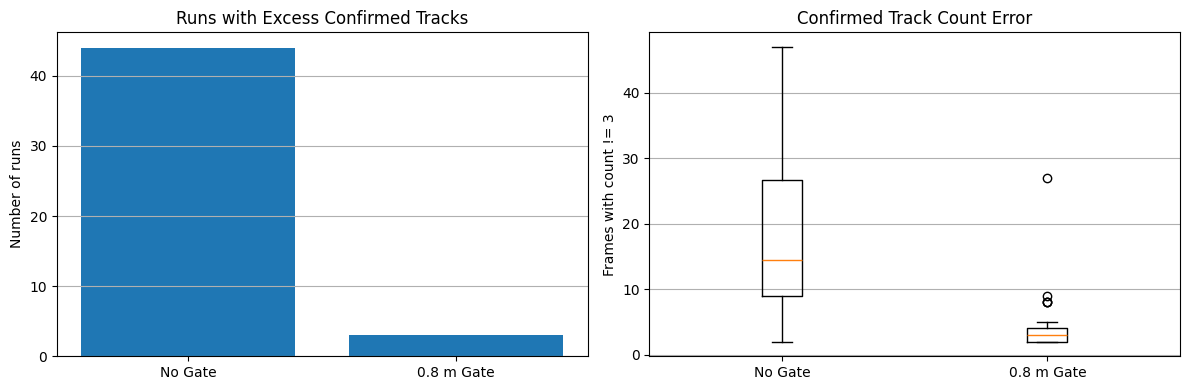

In [27]:

import numpy as np
import matplotlib.pyplot as plt

seeds = range(50)
gates = [0.0, 0.8]

validation = {}

for gate in gates:
    records = []

    for seed in seeds:
        result = run_tracker_v13(
            seed=seed,
            birth_gate=gate
        )

        counts = result["confirmed_counts"]

        records.append({
            "created": result["created"],
            "suppressed": result["suppressed"],
            "max_confirmed": counts.max(),
            "final_confirmed": counts[-1],
            "excess_frames": np.sum(counts > 3),
            "count_error_frames": np.sum(counts != 3)
        })

    validation[gate] = records

print("=== TRACK MANAGEMENT VALIDATION ===")

for gate in gates:
    records = validation[gate]

    excess_runs = sum(
        r["excess_frames"] > 0 for r in records
    )

    avg_created = np.mean([
        r["created"] for r in records
    ])

    avg_excess = np.mean([
        r["excess_frames"] for r in records
    ])

    avg_count_error = np.mean([
        r["count_error_frames"] for r in records
    ])

    print(f"\nBirth Gate: {gate:.1f} m")
    print(f"Runs with excess tracks: {excess_runs}/50")
    print(f"Mean tracks created: {avg_created:.2f}")
    print(f"Mean excess-track frames: {avg_excess:.2f}")
    print(f"Mean count-error frames: {avg_count_error:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

labels = ["No Gate", "0.8 m Gate"]

axes[0].bar(
    labels,
    [
        sum(r["excess_frames"] > 0
            for r in validation[g])
        for g in gates
    ]
)
axes[0].set_title("Runs with Excess Confirmed Tracks")
axes[0].set_ylabel("Number of runs")

axes[1].boxplot(
    [
        [r["count_error_frames"]
         for r in validation[g]]
        for g in gates
    ],
    tick_labels=labels
)
axes[1].set_title("Confirmed Track Count Error")
axes[1].set_ylabel("Frames with count != 3")

for ax in axes:
    ax.grid(axis="y")

plt.tight_layout()
plt.show()


=== CLOSE TARGET STRESS TEST ===
Distance | Gate | Undertrack | Overtrack | Exact
  2.0 m | 0.0 m |     0.0% |    16.0% |    84.0%
  2.0 m | 0.8 m |     0.0% |     0.9% |    99.1%
  1.0 m | 0.0 m |     0.0% |    15.0% |    85.0%
  1.0 m | 0.8 m |     0.0% |     0.9% |    99.1%
  0.8 m | 0.0 m |     0.0% |    19.1% |    80.9%
  0.8 m | 0.8 m |     0.0% |     0.9% |    99.1%
  0.6 m | 0.0 m |     0.0% |    19.0% |    81.0%
  0.6 m | 0.8 m |     0.4% |     0.4% |    99.2%
  0.4 m | 0.0 m |     0.0% |    16.8% |    83.2%
  0.4 m | 0.8 m |     5.1% |     0.0% |    94.9%
  0.2 m | 0.0 m |     0.0% |    15.7% |    84.3%
  0.2 m | 0.8 m |    10.0% |     0.6% |    89.4%


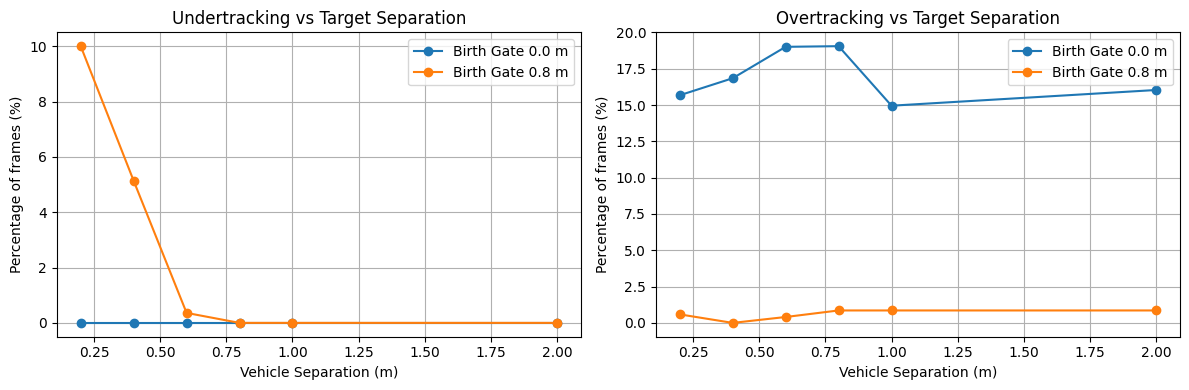

In [28]:

import numpy as np
import matplotlib.pyplot as plt

# Preserve original scenario
original_truth_multi = truth_multi.copy()

separations = [2.0, 1.0, 0.8, 0.6, 0.4, 0.2]
seeds = range(20)
gates = [0.0, 0.8]

stress_results = {}

try:
    for distance in separations:

        # Two vehicles with parallel trajectories
        vehicle_1 = np.column_stack((
            10 + 1.2*T,
            2 + 0.15*T
        ))

        vehicle_2 = np.column_stack((
            10 + 1.2*T,
            2 + distance + 0.15*T
        ))

        pedestrian = np.column_stack((
            18 + 0.25*T,
            -3 + 0.6*T
        ))

        # This function reads truth_multi globally
        truth_multi = np.stack([
            vehicle_1, vehicle_2, pedestrian
        ])

        for gate in gates:
            records = []

            for seed in seeds:
                result = run_tracker_v13(
                    seed=seed,
                    birth_gate=gate
                )

                counts = result["confirmed_counts"]

                # Ignore the first second for
                # confirmation initialization
                mask = T >= 1.0

                records.append({
                    "mean_confirmed": counts[mask].mean(),
                    "undertrack_fraction":
                        np.mean(counts[mask] < 3),
                    "overtrack_fraction":
                        np.mean(counts[mask] > 3),
                    "exact_count_fraction":
                        np.mean(counts[mask] == 3)
                })

            stress_results[(distance, gate)] = records

finally:
    # Restore original project scenario
    truth_multi = original_truth_multi


print("=== CLOSE TARGET STRESS TEST ===")
print("Distance | Gate | Undertrack | Overtrack | Exact")

for distance in separations:
    for gate in gates:
        records = stress_results[(distance, gate)]

        under = np.mean([
            r["undertrack_fraction"] for r in records
        ])
        over = np.mean([
            r["overtrack_fraction"] for r in records
        ])
        exact = np.mean([
            r["exact_count_fraction"] for r in records
        ])

        print(
            f"{distance:5.1f} m | "
            f"{gate:3.1f} m | "
            f"{under:8.1%} | "
            f"{over:8.1%} | "
            f"{exact:8.1%}"
        )


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for gate in gates:
    under_rates = []
    over_rates = []

    for distance in separations:
        records = stress_results[(distance, gate)]

        under_rates.append(np.mean([
            r["undertrack_fraction"] for r in records
        ]))

        over_rates.append(np.mean([
            r["overtrack_fraction"] for r in records
        ]))

    axes[0].plot(
        separations, np.array(under_rates)*100,
        "o-", label=f"Birth Gate {gate} m"
    )

    axes[1].plot(
        separations, np.array(over_rates)*100,
        "o-", label=f"Birth Gate {gate} m"
    )

axes[0].set_title("Undertracking vs Target Separation")
axes[1].set_title("Overtracking vs Target Separation")

for ax in axes:
    ax.set_xlabel("Vehicle Separation (m)")
    ax.set_ylabel("Percentage of frames (%)")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


In [29]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

def identity_evaluation(separation, gate, seed=2027):
    global truth_multi

    original = truth_multi.copy()

    try:
        truth_multi = np.stack([
            np.column_stack((
                10 + 1.2*T,
                2 + 0.15*T
            )),
            np.column_stack((
                10 + 1.2*T,
                2 + separation + 0.15*T
            )),
            np.column_stack((
                18 + 0.25*T,
                -3 + 0.6*T
            ))
        ])

        result = run_tracker_v13(
            seed=seed,
            birth_gate=gate
        )

        previous_id = {}
        switches = 0
        matched = 0
        unmatched = 0
        missed = 0

        for k, t in enumerate(T):
            if t < 1.0:
                continue

            active = []

            for tr in result["tracks"]:
                for h in tr.history:
                    if (
                        abs(h[0] - t) < 1e-6
                        and h[3] == "confirmed"
                    ):
                        active.append(
                            (tr.id, np.array(h[1:3]))
                        )
                        break

            if not active:
                missed += 3
                continue

            positions = np.array([
                item[1] for item in active
            ])

            distances = np.linalg.norm(
                truth_multi[:, k, None, :] -
                positions[None, :, :],
                axis=2
            )

            rows, cols = linear_sum_assignment(distances)
            valid_tracks = set()
            valid_gt = set()

            for gt_id, track_idx in zip(rows, cols):
                if distances[gt_id, track_idx] > 0.75:
                    continue

                track_id = active[track_idx][0]

                if (
                    gt_id in previous_id
                    and previous_id[gt_id] != track_id
                ):
                    switches += 1

                previous_id[gt_id] = track_id
                valid_tracks.add(track_idx)
                valid_gt.add(gt_id)
                matched += 1

            unmatched += len(active) - len(valid_tracks)
            missed += 3 - len(valid_gt)

        return switches, matched, unmatched, missed

    finally:
        truth_multi = original


print("=== IDENTITY STRESS TEST ===")
print("Distance | Gate | Switches | Matched | Unmatched | Missed")

for distance in [2.0, 0.4, 0.2]:
    for gate in [0.0, 0.8]:
        s, m, u, miss = identity_evaluation(
            distance, gate
        )
        print(
            f"{distance:5.1f} m | "
            f"{gate:3.1f} m | "
            f"{s:8d} | "
            f"{m:7d} | "
            f"{u:9d} | "
            f"{miss:6d}"
        )


=== IDENTITY STRESS TEST ===
Distance | Gate | Switches | Matched | Unmatched | Missed
  2.0 m | 0.0 m |        0 |     333 |        12 |      0
  2.0 m | 0.8 m |        0 |     333 |         0 |      0
  0.4 m | 0.0 m |        2 |     333 |         9 |      0
  0.4 m | 0.8 m |        0 |     333 |         0 |      0
  0.2 m | 0.0 m |       10 |     333 |         7 |      0
  0.2 m | 0.8 m |       12 |     333 |         0 |      0


Identity changes: 12
Object 0: t=3.0s, Track 1 -> 2
Object 0: t=9.4s, Track 2 -> 1
Object 0: t=9.5s, Track 1 -> 2
Object 0: t=9.7s, Track 2 -> 1
Object 0: t=9.8s, Track 1 -> 2
Object 0: t=9.9s, Track 2 -> 1
Object 1: t=3.0s, Track 2 -> 1
Object 1: t=9.4s, Track 1 -> 2
Object 1: t=9.5s, Track 2 -> 1
Object 1: t=9.7s, Track 1 -> 2
Object 1: t=9.8s, Track 2 -> 1
Object 1: t=9.9s, Track 1 -> 2


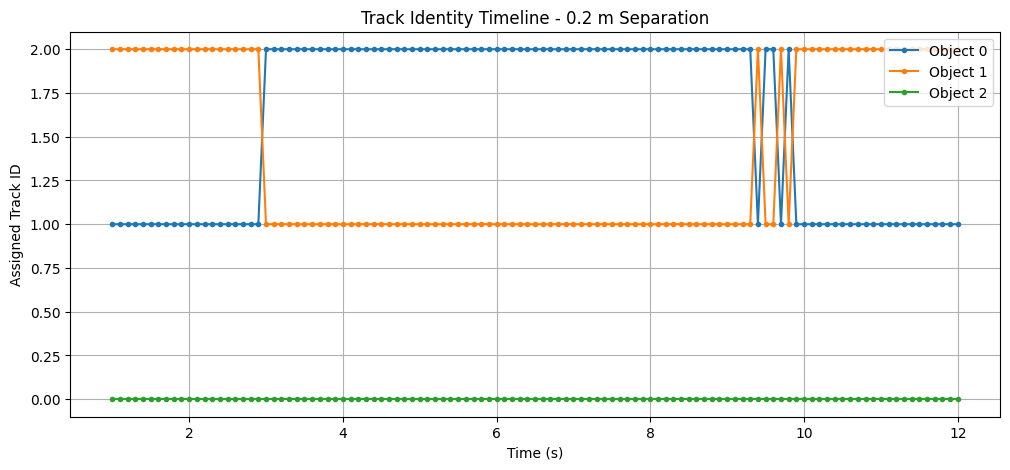

In [30]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

separation = 0.2

vehicle1 = np.column_stack((
    10 + 1.2*T, 2 + 0.15*T
))
vehicle2 = vehicle1 + np.array([0.0, separation])
pedestrian = np.column_stack((
    18 + 0.25*T, -3 + 0.6*T
))

original_truth = truth_multi.copy()

try:
    truth_multi = np.stack([
        vehicle1, vehicle2, pedestrian
    ])
    result = run_tracker_v13(
        seed=2027,
        birth_gate=0.8
    )
finally:
    truth_multi = original_truth

track_lookup = {}
for tr in result["tracks"]:
    for t, x, y, status in tr.history:
        if status == "confirmed":
            k = int(np.argmin(abs(T-t)))
            track_lookup.setdefault(k, []).append(
                (tr.id, np.array([x, y]))
            )

identities = np.full((3, len(T)), np.nan)
switch_events = []

for k, t in enumerate(T):
    if t < 1.0:
        continue

    active = track_lookup.get(k, [])
    if not active:
        continue

    positions = np.array([p for _, p in active])
    gt = np.stack([
        vehicle1[k], vehicle2[k], pedestrian[k]
    ])

    D = np.linalg.norm(
        gt[:, None, :] - positions[None, :, :],
        axis=2
    )

    rows, cols = linear_sum_assignment(D)

    for i, j in zip(rows, cols):
        if D[i, j] > 0.75:
            continue
        identities[i, k] = active[j][0]

for i in range(3):
    observed = np.where(np.isfinite(identities[i]))[0]
    for a, b in zip(observed[:-1], observed[1:]):
        if identities[i, a] != identities[i, b]:
            switch_events.append((
                i, T[b],
                int(identities[i, a]),
                int(identities[i, b])
            ))

print("Identity changes:", len(switch_events))
for obj, t, old, new in switch_events:
    print(
        f"Object {obj}: t={t:.1f}s, "
        f"Track {old} -> {new}"
    )

plt.figure(figsize=(12, 5))
for i in range(3):
    plt.plot(
        T, identities[i],
        ".-", label=f"Object {i}"
    )
plt.xlabel("Time (s)")
plt.ylabel("Assigned Track ID")
plt.title("Track Identity Timeline - 0.2 m Separation")
plt.grid(True)
plt.legend()
plt.show()


=== INTEGRATED SENSOR STREAM v2.0 ===
Targets: 3
Radar detections: 263
Received V2X LiDAR detections: 329
Mean V2X reception delay: 0.300 s


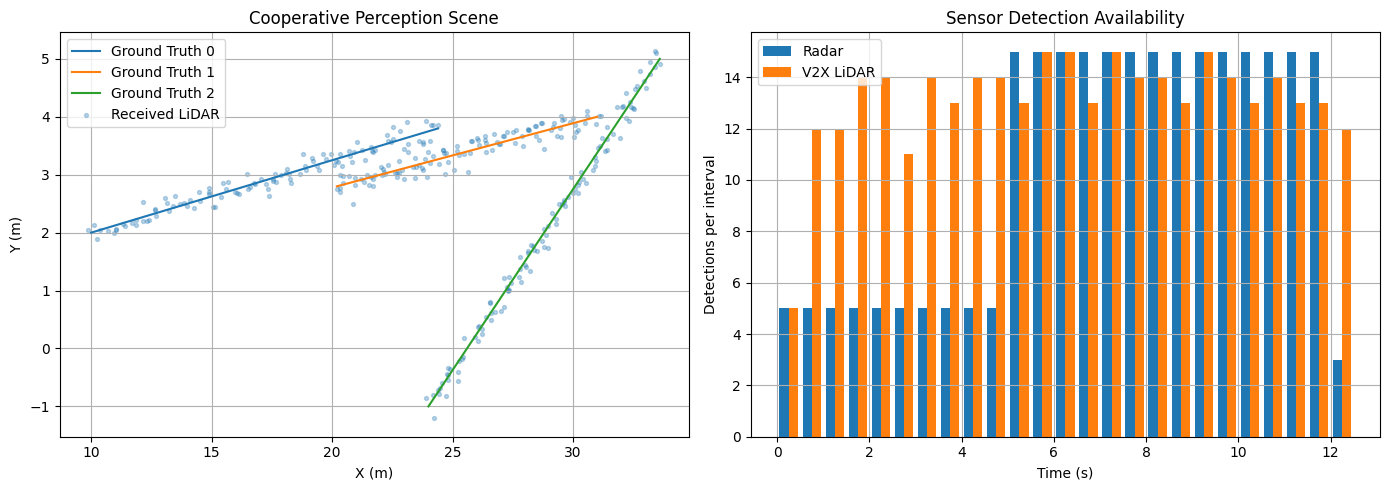

In [31]:

import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass

@dataclass
class Detection:
    arrival_time: float
    measurement_time: float
    sensor: str
    z: np.ndarray

rng = np.random.default_rng(2028)
dt = 0.1
times_v2 = np.round(np.arange(0, 12.01, dt), 6)

ego = np.array([0., 0.])
roadside = np.array([22., 15.])

# Three moving objects
targets_v2 = np.stack([
    np.column_stack((10 + 1.2*times_v2,
                     2 + 0.15*times_v2)),
    np.column_stack((31 - 0.9*times_v2,
                     4 - 0.10*times_v2)),
    np.column_stack((24 + 0.8*times_v2,
                     -1 + 0.5*times_v2))
])

velocities = np.array([
    [1.2, 0.15],
    [-0.9, -0.10],
    [0.8, 0.5]
])

radar_std = np.array([
    0.20, np.deg2rad(0.5), 0.10
])
lidar_std = 0.12
latency = 0.3
packet_loss = 0.10

events = []

for k, t in enumerate(times_v2):
    blocker = (
        np.array([12., 0.])
        if t < 5.0 else np.array([12., 8.])
    )

    for obj in range(3):
        p = targets_v2[obj, k]
        v = velocities[obj]

        # Radar visibility: geometric occlusion
        visible_radar = not is_occluded(
            ego, p, blocker, 2.0
        )

        if visible_radar:
            relative = p - ego
            r = np.linalg.norm(relative)
            theta = np.arctan2(relative[1], relative[0])
            radial_v = np.dot(relative, v) / r

            z = np.array([r, theta, radial_v])
            z += rng.normal(0, radar_std)
            z[1] = (z[1] + np.pi) % (2*np.pi) - np.pi

            events.append(Detection(
                float(t), float(t), "radar", z
            ))

        # Roadside LiDAR visibility
        visible_lidar = not is_occluded(
            roadside, p, blocker, 2.0
        )

        if visible_lidar and rng.random() >= packet_loss:
            z = p + rng.normal(0, lidar_std, 2)

            # Arrival aligned to next receiver simulation step
            arrival = np.ceil(
                (t + latency - 1e-9) / dt
            ) * dt

            events.append(Detection(
                round(float(arrival), 6),
                float(t), "lidar", z
            ))

# Do not pass ground-truth object IDs to tracking.
events.sort(key=lambda e: e.arrival_time)

radar_events = [e for e in events if e.sensor == "radar"]
lidar_events = [e for e in events if e.sensor == "lidar"]

print("=== INTEGRATED SENSOR STREAM v2.0 ===")
print("Targets:", targets_v2.shape[0])
print("Radar detections:", len(radar_events))
print("Received V2X LiDAR detections:", len(lidar_events))

if lidar_events:
    delays = np.array([
        e.arrival_time - e.measurement_time
        for e in lidar_events
    ])
    print(f"Mean V2X reception delay: {delays.mean():.3f} s")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for obj in range(3):
    axes[0].plot(
        targets_v2[obj, :, 0],
        targets_v2[obj, :, 1],
        label=f"Ground Truth {obj}"
    )

lidar_xy = np.array([e.z for e in lidar_events])
if len(lidar_xy):
    axes[0].scatter(
        lidar_xy[:, 0],
        lidar_xy[:, 1],
        s=8, alpha=0.3,
        label="Received LiDAR"
    )

axes[0].set_title("Cooperative Perception Scene")
axes[0].set_xlabel("X (m)")
axes[0].set_ylabel("Y (m)")
axes[0].legend()
axes[0].grid(True)

radar_t = [e.measurement_time for e in radar_events]
lidar_t = [e.arrival_time for e in lidar_events]

axes[1].hist(
    [radar_t, lidar_t],
    bins=np.arange(0, 12.6, 0.5),
    label=["Radar", "V2X LiDAR"]
)
axes[1].set_title("Sensor Detection Availability")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Detections per interval")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


=== MULTI-OBJECT COOPERATIVE EKF ===
Radar Only               | Final tracks: 3 | Max tracks: 3
Naive Fusion             | Final tracks: 5 | Max tracks: 5
Latency-Aware Fusion     | Final tracks: 3 | Max tracks: 3


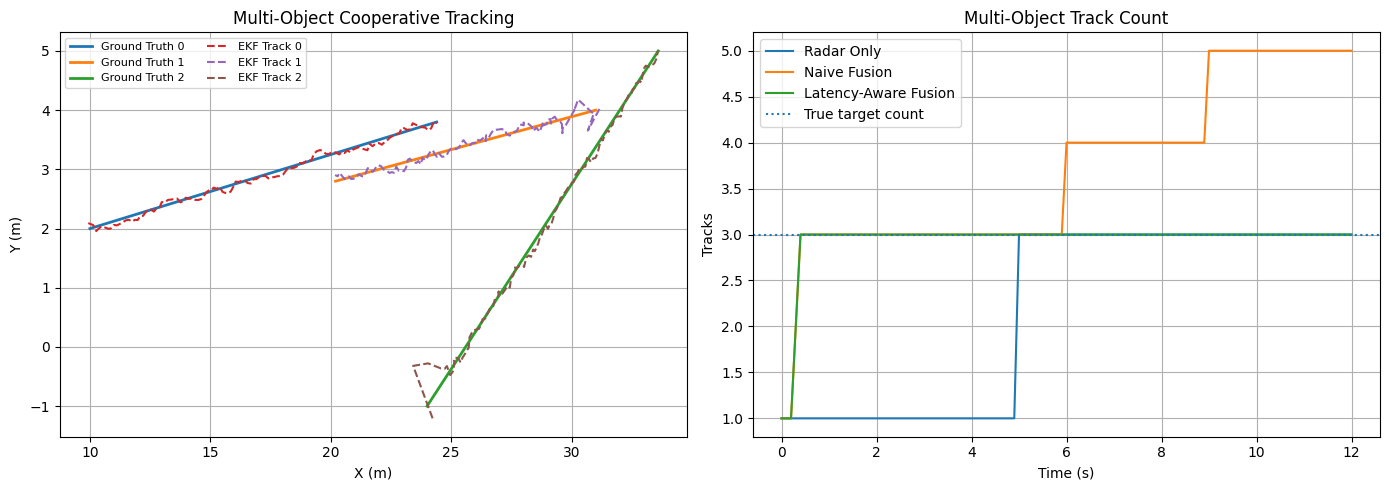

In [32]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from itertools import groupby

# ==========================================
# 1. Multi-object EKF
# ==========================================

class MultiEKF:
    def __init__(self, z, sensor, t, track_id):
        self.id = track_id
        self.t = float(t)
        self.hits = 1

        if sensor == "radar":
            r, angle, vr = z
            c, s = np.cos(angle), np.sin(angle)
            self.x = np.array([
                r*c, r*s, vr*c, vr*s
            ])
            self.P = np.diag([0.5, 0.5, 4.0, 4.0])
        else:
            self.x = np.array([z[0], z[1], 0., 0.])
            self.P = np.diag([0.12**2, 0.12**2, 4., 4.])

    def predict(self, t):
        dt = float(t - self.t)
        if dt < -1e-8:
            raise ValueError("Backward prediction")
        dt = max(dt, 0.)

        F = np.eye(4)
        F[0, 2] = dt
        F[1, 3] = dt

        G = np.array([
            [dt**2/2, 0],
            [0, dt**2/2],
            [dt, 0],
            [0, dt]
        ])
        Q = 0.6**2 * G @ G.T

        self.x = F @ self.x
        self.P = F @ self.P @ F.T + Q
        self.t = float(t)

    def model(self, sensor):
        if sensor == "lidar":
            H = np.array([
                [1., 0., 0., 0.],
                [0., 1., 0., 0.]
            ])
            zhat = H @ self.x
            R = np.eye(2) * lidar_std**2
        else:
            px, py, vx, vy = self.x
            r = max(np.hypot(px, py), 1e-6)
            r2 = r*r
            dot = px*vx + py*vy

            zhat = np.array([
                r, np.arctan2(py, px), dot/r
            ])

            H = np.array([
                [px/r, py/r, 0, 0],
                [-py/r2, px/r2, 0, 0],
                [vx/r-dot*px/r**3,
                 vy/r-dot*py/r**3, px/r, py/r]
            ])
            R = np.diag(radar_std**2)

        return zhat, H, R

    def innovation(self, z, sensor):
        zhat, H, R = self.model(sensor)
        y = np.asarray(z) - zhat

        if sensor == "radar":
            y[1] = (y[1] + np.pi) % (2*np.pi) - np.pi

        S = H @ self.P @ H.T + R
        d2 = float(y @ np.linalg.solve(S, y))
        return y, H, R, S, d2

    def update(self, z, sensor):
        y, H, R, S, _ = self.innovation(z, sensor)
        K = np.linalg.solve(S, H @ self.P).T

        self.x += K @ y
        A = np.eye(4) - K @ H
        self.P = A @ self.P @ A.T + K @ R @ K.T
        self.P = (self.P + self.P.T) / 2
        self.hits += 1


# ==========================================
# 2. Hungarian data association
# ==========================================

def associate_scan(tracks, detections, sensor, t, next_id):
    for tr in tracks:
        tr.predict(t)

    if not detections:
        return next_id

    n, m = len(tracks), len(detections)
    threshold = 11.34 if sensor == "radar" else 9.21
    cost = np.full((n, m), 1e6)

    for i, tr in enumerate(tracks):
        for j, det in enumerate(detections):
            d2 = tr.innovation(det.z, sensor)[4]
            if d2 <= threshold:
                cost[i, j] = d2

    assigned = set()

    if n and m:
        rows, cols = linear_sum_assignment(cost)
        for i, j in zip(rows, cols):
            if cost[i, j] <= threshold:
                tracks[i].update(detections[j].z, sensor)
                assigned.add(j)

    # Initial experimental track-birth exclusion
    for j, det in enumerate(detections):
        if j in assigned:
            continue

        if sensor == "radar":
            r, angle = det.z[:2]
            pos = np.array([
                r*np.cos(angle),
                r*np.sin(angle)
            ])
        else:
            pos = np.asarray(det.z[:2])

        if any(
            np.linalg.norm(tr.x[:2] - pos) < 0.8
            for tr in tracks
        ):
            continue

        tracks.append(MultiEKF(
            det.z, sensor, t, next_id
        ))
        next_id += 1

    return next_id


# ==========================================
# 3. Causal timestamp-aware replay
# ==========================================

def tracker_at(current_time, all_events, aware=True):
    available = [
        e for e in all_events
        if e.arrival_time <= current_time + 1e-8
    ]

    # Process measurements without GT object IDs
    available.sort(key=lambda e: (
        e.measurement_time if aware else e.arrival_time,
        0 if e.sensor == "radar" else 1
    ))

    tracks = []
    next_id = 0

    for event_t, group in groupby(
        available,
        key=lambda e: (
            e.measurement_time if aware
            else e.arrival_time
        )
    ):
        batch = list(group)

        for sensor in ["radar", "lidar"]:
            scan = [
                e for e in batch if e.sensor == sensor
            ]

            if scan:
                next_id = associate_scan(
                    tracks, scan, sensor,
                    event_t, next_id
                )

    for tr in tracks:
        tr.predict(current_time)

    return {
        tr.id: tr.x.copy()
        for tr in tracks
    }


# ==========================================
# 4. Run the integrated tracker
# ==========================================

radar_stream = [
    e for e in events if e.sensor == "radar"
]

methods = {
    "Radar Only": (radar_stream, True),
    "Naive Fusion": (events, False),
    "Latency-Aware Fusion": (events, True)
}

outputs = {}

for name, (stream, aware) in methods.items():
    outputs[name] = [
        tracker_at(float(t), stream, aware)
        for t in times_v2
    ]

print("=== MULTI-OBJECT COOPERATIVE EKF ===")

for name, history in outputs.items():
    counts = np.array([len(h) for h in history])
    print(
        f"{name:24s} | "
        f"Final tracks: {counts[-1]} | "
        f"Max tracks: {counts.max()}"
    )


# ==========================================
# 5. Visualization
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for j in range(3):
    axes[0].plot(
        targets_v2[j, :, 0],
        targets_v2[j, :, 1],
        linewidth=2,
        label=f"Ground Truth {j}"
    )

aware_history = outputs["Latency-Aware Fusion"]

track_ids = sorted(set(
    tid for frame in aware_history for tid in frame
))

for tid in track_ids:
    points = np.array([
        frame.get(tid, np.full(4, np.nan))[:2]
        for frame in aware_history
    ])

    axes[0].plot(
        points[:, 0],
        points[:, 1],
        "--",
        label=f"EKF Track {tid}"
    )

axes[0].set_title("Multi-Object Cooperative Tracking")
axes[0].set_xlabel("X (m)")
axes[0].set_ylabel("Y (m)")
axes[0].legend(fontsize=8, ncol=2)
axes[0].grid(True)

for name, history in outputs.items():
    axes[1].plot(
        times_v2,
        [len(frame) for frame in history],
        label=name
    )

axes[1].axhline(
    3, linestyle=":", label="True target count"
)
axes[1].set_title("Multi-Object Track Count")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Tracks")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


=== MULTI-OBJECT EVALUATION v2.2 ===
Method                   |     RMSE |  False | Missed
Radar Only               |   0.1123 |      0 |     80
Naive Fusion             |   0.2477 |     92 |      0
Latency-Aware Fusion     |   0.0888 |      0 |      0


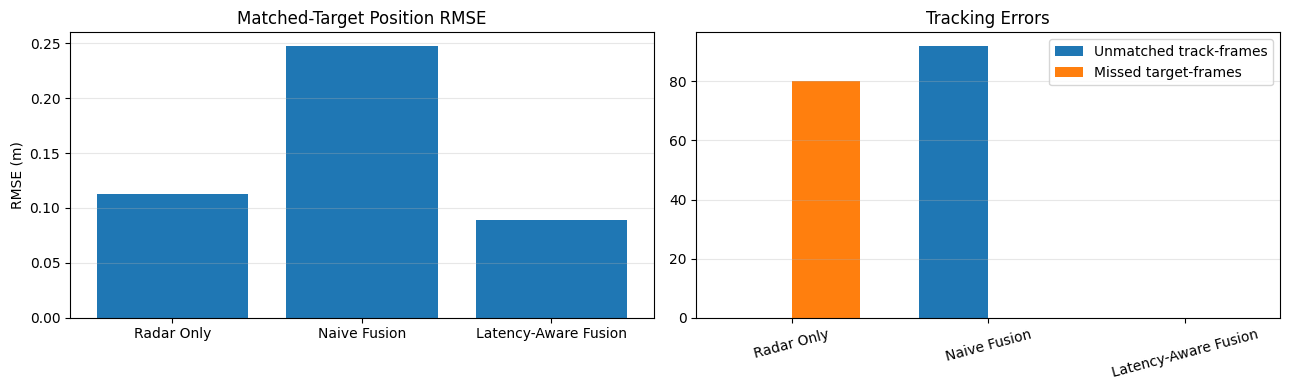

In [34]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

MATCH_GATE = 1.0  # meters
WARMUP_TIME = 1.0

def evaluate_multi_tracker(history, ground_truth, times):
    position_errors = []
    false_tracks = []
    missed_targets = []
    matched_counts = []

    for k, t in enumerate(times):
        if t < WARMUP_TIME:
            continue

        frame = history[k]
        gt = ground_truth[:, k, :]

        ids = list(frame.keys())
        positions = np.array(
            [frame[i][:2] for i in ids],
            dtype=float
        ).reshape(-1, 2)

        n_gt = len(gt)
        n_tracks = len(positions)

        if n_tracks == 0:
            false_tracks.append(0)
            missed_targets.append(n_gt)
            matched_counts.append(0)
            continue

        D = np.linalg.norm(
            gt[:, None, :] - positions[None, :, :],
            axis=2
        )

        # One-to-one matching with dummy assignments
        penalty = MATCH_GATE + 1.0
        size = n_gt + n_tracks
        C = np.zeros((size, size))
        C[:n_gt, :n_tracks] = np.where(
            D <= MATCH_GATE, D, 3 * penalty
        )
        C[:n_gt, n_tracks:] = penalty
        C[n_gt:, :n_tracks] = penalty

        rows, cols = linear_sum_assignment(C)

        valid = [
            (i, j) for i, j in zip(rows, cols)
            if i < n_gt and j < n_tracks
            and D[i, j] <= MATCH_GATE
        ]

        for i, j in valid:
            position_errors.append(D[i, j]**2)

        matched = len(valid)
        matched_counts.append(matched)
        false_tracks.append(n_tracks - matched)
        missed_targets.append(n_gt - matched)

    rmse = (
        np.sqrt(np.mean(position_errors))
        if position_errors else np.nan
    )

    return {
        "rmse": rmse,
        "false_track_frames": sum(false_tracks),
        "missed_target_frames": sum(missed_targets),
        "mean_matched": np.mean(matched_counts),
        "false_timeline": np.array(false_tracks),
        "missed_timeline": np.array(missed_targets)
    }


evaluation_v22 = {}

for name, history in outputs.items():
    evaluation_v22[name] = evaluate_multi_tracker(
        history, targets_v2, times_v2
    )

print("=== MULTI-OBJECT EVALUATION v2.2 ===")
print(
    f"{'Method':24s} | {'RMSE':>8s} | "
    f"{'False':>6s} | {'Missed':>6s}"
)

for name, result in evaluation_v22.items():
    print(
        f"{name:24s} | "
        f"{result['rmse']:8.4f} | "
        f"{result['false_track_frames']:6d} | "
        f"{result['missed_target_frames']:6d}"
    )


fig, axes = plt.subplots(1, 2, figsize=(13, 4))

names = list(evaluation_v22.keys())

axes[0].bar(
    names,
    [evaluation_v22[n]["rmse"] for n in names]
)
axes[0].set_title("Matched-Target Position RMSE")
axes[0].set_ylabel("RMSE (m)")

x = np.arange(len(names))
width = 0.35

axes[1].bar(
    x - width/2,
    [evaluation_v22[n]["false_track_frames"]
     for n in names],
    width, label="Unmatched track-frames"
)

axes[1].bar(
    x + width/2,
    [evaluation_v22[n]["missed_target_frames"]
     for n in names],
    width, label="Missed target-frames"
)

axes[1].set_xticks(x)
axes[1].set_xticklabels(names, rotation=15)
axes[1].set_title("Tracking Errors")
axes[1].legend()

for ax in axes:
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
